# Bankruptcy Prediction — MF815 Machine Learning


In [ ]:
# Run this cell once to install required packages :)
%pip install -q numpy pandas scipy matplotlib seaborn scikit-learn xgboost lightgbm catboost imbalanced-learn optuna pyod

In [ ]:
# ── Standard Libraries ────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
from scipy import stats
from scipy.stats import rankdata
import warnings
warnings.filterwarnings('ignore')

# ── Visualization ─────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set_theme(style='ticks', palette='muted')
sns.set_context('paper', font_scale=1.2)

# ── Scikit-learn: Model Selection & Metrics ───────────────────────────────────
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             roc_auc_score, precision_recall_curve)
from sklearn.feature_selection import RFECV
from sklearn.preprocessing import PowerTransformer
from sklearn.base import BaseEstimator, ClassifierMixin, clone

# ── Scikit-learn: Models ──────────────────────────────────────────────────────
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

# ── Gradient Boosting ─────────────────────────────────────────────────────────
import xgboost as xgb
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# ── Imbalanced-learn ──────────────────────────────────────────────────────────
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.combine import SMOTEENN, SMOTETomek

# ── Hyperparameter Tuning ─────────────────────────────────────────────────────
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

# ── Outlier Detection ─────────────────────────────────────────────────────────
from pyod.models.ecod import ECOD

# 1. EDA

In [24]:
train_raw = pd.read_csv('train.csv')
test_raw  = pd.read_csv('test.csv')

train_raw.columns = train_raw.columns.str.strip()                          
test_raw.columns  = test_raw.columns.str.strip()                                                                                                        
# Rename target column
train_raw.rename(columns={'Bankrupt?': 'Bankrupt'}, inplace=True)          
                  
print(f"Train shape: {train_raw.shape}  |  Test shape: {test_raw.shape}")
print(f"\nTarget: {'Bankrupt?' in train_raw.columns}")
print(f"\nTarget distribution:\n{train_raw['Bankrupt'].value_counts()}")
    

Train shape: (5455, 97)  |  Test shape: (1364, 96)

Target: False

Target distribution:
Bankrupt
0    5285
1     170
Name: count, dtype: int64


In [25]:
train_raw.info() #96 features + 1 target 

# Datatype of columns
print("\nDatatype of Features :")
print(train_raw.dtypes.value_counts())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5455 entries, 0 to 5454
Data columns (total 97 columns):
 #   Column                                                   Non-Null Count  Dtype  
---  ------                                                   --------------  -----  
 0   Unnamed: 0                                               5455 non-null   int64  
 1   ROA(C) before interest and depreciation before interest  5455 non-null   float64
 2   ROA(A) before interest and % after tax                   5455 non-null   float64
 3   ROA(B) before interest and depreciation after tax        5455 non-null   float64
 4   Operating Gross Margin                                   5455 non-null   float64
 5   Realized Sales Gross Margin                              5455 non-null   float64
 6   Operating Profit Rate                                    5455 non-null   float64
 7   Pre-tax net Interest Rate                                5455 non-null   float64
 8   After-tax net Interest Rate 

> **Observations :**
> 
> * All the given features are numeric *(int64 or float64)*
> * Column *Net Income Flag* and *Liability-Assets Flag* looks like a catogorical columns (These features have "Flag" in its name)
>     * Bankrupt column is also an integer column
> * There is no missing values

=== Target Distribution ===
  Class 0: 5,285  (96.88%)
  Class 1: 170  (3.12%)


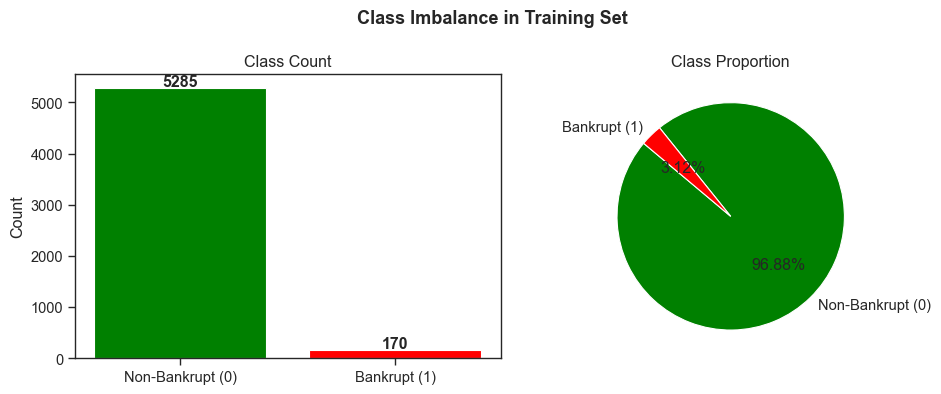


Imbalance ratio (0:1) ≈ 31.1:1  →  SMOTE or class_weight needed


In [26]:
counts = train_raw['Bankrupt'].value_counts()
pct    = train_raw['Bankrupt'].value_counts(normalize=True) * 100

print("=== Target Distribution ===")
for cls in [0, 1]:
    print(f"  Class {cls}: {counts[cls]:,}  ({pct[cls]:.2f}%)")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Bar chart
axes[0].bar(['Non-Bankrupt (0)', 'Bankrupt (1)'], counts.values,
            color=['green', 'red'], edgecolor='white')
axes[0].set_title('Class Count')
axes[0].set_ylabel('Count')
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 20, str(v), ha='center', fontweight='bold')

# Pie chart
axes[1].pie(counts.values, labels=['Non-Bankrupt (0)', 'Bankrupt (1)'],
            autopct='%1.2f%%', colors=['green', 'red'],
            startangle=140, wedgeprops=dict(edgecolor='white'))
axes[1].set_title('Class Proportion')

plt.suptitle('Class Imbalance in Training Set', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

imbalance_ratio = counts[0] / counts[1]
print(f"\nImbalance ratio (0:1) ≈ {imbalance_ratio:.1f}:1  →  SMOTE or class_weight needed")

### Class Imbalance — Key Observations

The training set has a **~30:1 majority-to-minority ratio**, which is a case of **severe class imbalance**.

As noted in Kuhn & Johnson (2019, Ch. 16), under severe imbalance:
- Models default to predicting the majority class almost exclusively
- Accuracy becomes a misleading metric (a model predicting all 0s scores ~97%)
- **Sensitivity (recall for the bankrupt class) collapses to near zero**

> *"The class imbalance overwhelms patterns useful for predicting the minority class."*

so, in the modeling part, I'll apply at least one remedy: `class_weight='balanced'`, `scale_pos_weight`, or **SMOTE**,  Use **Stratified K-Fold CV** to maintain the ~3% event rate in each fold, After training, **tune the probability threshold** on a held-out validation set to maximise F1 (default 0.5 is too high for the minority class)

## 1.2 Sentinel Value Analysis (values >= 1e9)

Columns with sentinel values (>= 1e9): 21 / 96

Top 20 by sentinel count:
                                       count  pct(%)
Total Asset Growth Rate                 4356   79.85
Cash Turnover Rate                      2759   50.58
Research and development expense rate   2387   43.76
Inventory Turnover Rate (times)         1810   33.18
Quick Asset Turnover Rate               1732   31.75
Operating Expense Rate                  1670   30.61
Current Asset Turnover Rate              875   16.04
Fixed Assets Turnover Frequency          851   15.60
Long-term Liability to Current Assets     59    1.08
Inventory/Current Liability               53    0.97
Cash/Current Liability                    31    0.57
Total assets to GNP price                 17    0.31
Accounts Receivable Turnover              11    0.20
Average Collection Days                   10    0.18
Allocation rate per person                 9    0.16
Quick Ratio                                6    0.11
Total debt/Total net wort

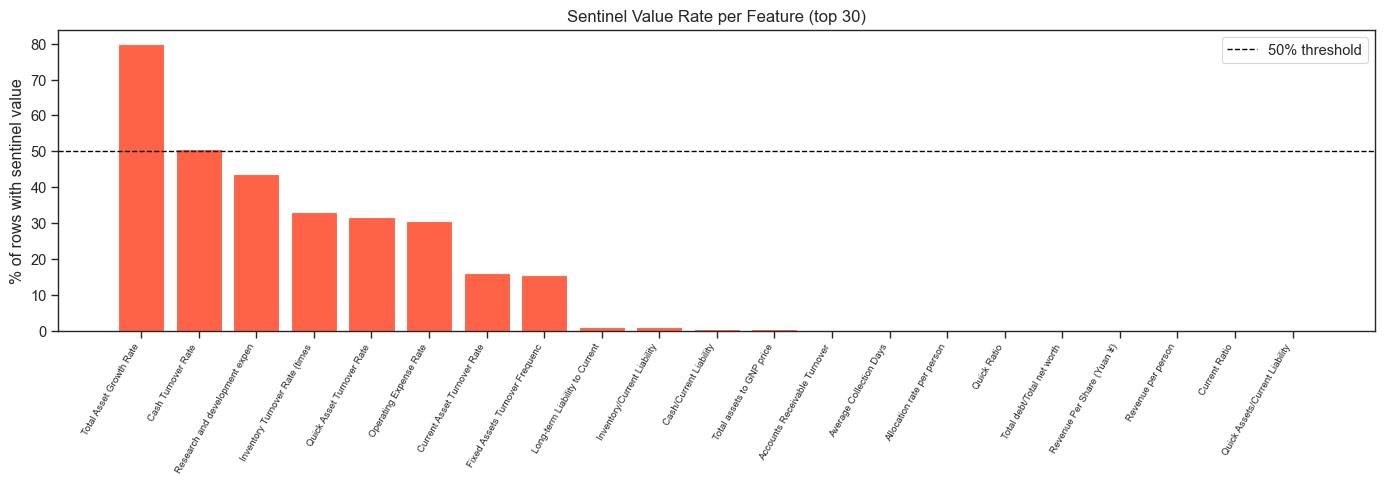

In [27]:
# Financial ratios should not exceed ~100x; values >= 1e9 are placeholder/sentinel
SENTINEL_THRESHOLD = 1e9
features_raw = [c for c in train_raw.columns if c != 'Bankrupt']
num_features  = train_raw[features_raw].select_dtypes(include=[np.number]).columns.tolist()

# Count sentinel entries per column
sentinel_counts = {}
for col in num_features:
    n = (train_raw[col] >= SENTINEL_THRESHOLD).sum()
    if n > 0:
        sentinel_counts[col] = n

sentinel_series = pd.Series(sentinel_counts).sort_values(ascending=False)
sentinel_pct    = (sentinel_series / len(train_raw) * 100).round(2)

print(f"Columns with sentinel values (>= 1e9): {len(sentinel_series)} / {len(num_features)}")
print(f"\nTop 20 by sentinel count:")
summary = pd.DataFrame({'count': sentinel_series, 'pct(%)': sentinel_pct}).head(20)
print(summary.to_string())

# Compare raw mean vs median to expose scale distortion
print("\nScale distortion check — columns where mean >> 100× median:")
distorted = []
for col in num_features:
    med = train_raw[col].median()
    mean = train_raw[col].mean()
    if med != 0 and abs(mean / med) > 100:
        distorted.append((col, round(mean, 2), round(med, 6)))
    elif med == 0 and mean > 1e6:
        distorted.append((col, round(mean, 2), med))
dist_df = pd.DataFrame(distorted, columns=['Feature', 'Mean', 'Median']).sort_values('Mean', ascending=False)
print(dist_df.to_string(index=False))

# Bar chart of sentinel rates
fig, ax = plt.subplots(figsize=(14, 5))
top30 = sentinel_pct.head(30)
ax.bar(range(len(top30)), top30.values, color='tomato', edgecolor='white')
ax.set_xticks(range(len(top30)))
ax.set_xticklabels([c[:30] for c in top30.index], rotation=60, ha='right', fontsize=7)
ax.axhline(50, color='black', linestyle='--', linewidth=1, label='50% threshold')
ax.set_title('Sentinel Value Rate per Feature (top 30)', fontsize=12)
ax.set_ylabel('% of rows with sentinel value')
ax.legend()
plt.tight_layout()
plt.show()

---
### Key Observations
                                                                             
  1. **Turnover-based ratios dominate** — most sentinel-heavy features are   
  turnover rates. This is expected: companies with zero inventory, zero fixed      
  assets, or zero revenue produce undefined ratios.
                                                                             
  2. **Sentinel values are informative** — the *presence* of a sentinel      
  (i.e., the ratio being undefined) may itself signal financial distress. Consider   
  adding binary indicator columns (e.g., `has_inventory = 0/1`) before replacing with NaN.                                                                  
                                                                             
  ### Preprocessing Actions                                                  
                                                       

### Sentinel Value Analysis (values >= 1e9)

  21 out of 95 features contain sentinel values, which represent             
  undefined/impossible
  financial ratios (e.g., division by zero) encoded as large numbers rather  
  than NaN.                                                                  
  These must be replaced with NaN before imputation.
                                                                             
  #### Severity Tiers                                                         
                                                                             
  **Tier 1 — Critical (>30%): Drop or treat with extreme caution**           
  | Feature | Sentinel % | Reason likely undefined |
  |---|---|---|                                                              
  | Total Asset Growth Rate | 79.85% | No prior-year assets to compare |
  | Cash Turnover Rate | 50.58% | Zero or missing cash balance |             
  | Research and development expense rate | 43.76% | No R&D spend (common in 
  non-tech firms) |                                                          
  | Inventory Turnover Rate | 33.18% | Zero inventory (service companies) |  
  | Quick Asset Turnover Rate | 31.75% | Zero quick assets |                 
  | Operating Expense Rate | 30.61% | Zero or missing revenue |              
                                                                             
  → Total Asset Growth Rate (79.85%) **dropped**,
  → Others in this tier: retain but flag; after sentinel→NaN conversion,     
  missing rate                                                               
    will exceed 30%, so median imputation may introduce significant noise.
                                                                             
  **Tier 2 — Moderate (1–30%): Impute with median**                          
  | Feature | Sentinel % |                                                   
  |---|---|                                                                  
  | Current Asset Turnover Rate | 16.04% |
  | Fixed Assets Turnover Frequency | 15.60% |                               
  | Long-term Liability to Current Assets | 1.08% |
  | Inventory/Current Liability | 0.97% |                                    
  | Cash/Current Liability | 0.57% |
                                                                             
  → Safe to impute with training-set median after sentinel→NaN conversion.   
                                                                             
  **Tier 3 — Minor (<1%): Impute normally**                                  
  Remaining features (Total assets to GNP price, Accounts Receivable
  Turnover,                                                                  
  Average Collection Days, etc.) have <1% sentinel rate — negligible impact.
                                                                             
  



### Replace Sentinel Values with NaN

In [28]:
SENTINEL_THRESHOLD = 1e9
train = train_raw.copy()
test  = test_raw.copy()


BINARY_COLS = ['Liability-Assets Flag', 'Net Income Flag'] # exclude binary flags and target
TARGET_COL  = 'Bankrupt'

feat_cols = [c for c in train.columns
             if c not in BINARY_COLS + [TARGET_COL]]

# Replace sentinel values with NaN (train and test separately)
sentinel_mask_train = train[feat_cols] >= SENTINEL_THRESHOLD
sentinel_mask_test  = test[feat_cols]  >= SENTINEL_THRESHOLD
train[feat_cols] = train[feat_cols].where(~sentinel_mask_train, other=np.nan)
test[feat_cols]  = test[feat_cols].where(~sentinel_mask_test,  other=np.nan)

# Summary
n_replaced_train = sentinel_mask_train.sum().sum()
n_replaced_test  = sentinel_mask_test.sum().sum()
print(f"Sentinel values replaced → NaN")
print(f"  Train: {n_replaced_train:,} cells across {sentinel_mask_train.any().sum()} columns")
print(f"  Test:  {n_replaced_test:,} cells across {sentinel_mask_test.any().sum()} columns")

# Verify
assert (train[feat_cols] >= SENTINEL_THRESHOLD).sum().sum() == 0, "Sentinels remain in train!"
assert (test[feat_cols]  >= SENTINEL_THRESHOLD).sum().sum() == 0, "Sentinels remain in test!"
print("\nAssertion passed: no sentinel values remain.")

Sentinel values replaced → NaN
  Train: 16,647 cells across 21 columns
  Test:  4,151 cells across 21 columns

Assertion passed: no sentinel values remain.


---
## 1.3 Missing Value Analysis (post sentinel replacement)

Features with any missing values: 21 / 94

Columns exceeding 50% threshold (will be dropped):
                         missing_count  missing_pct
Total Asset Growth Rate           4356        79.85
Cash Turnover Rate                2759        50.58

All missing columns (sorted):
                                       missing_count  missing_pct
Total Asset Growth Rate                         4356        79.85
Cash Turnover Rate                              2759        50.58
Research and development expense rate           2387        43.76
Inventory Turnover Rate (times)                 1810        33.18
Quick Asset Turnover Rate                       1732        31.75
Operating Expense Rate                          1670        30.61
Current Asset Turnover Rate                      875        16.04
Fixed Assets Turnover Frequency                  851        15.60
Long-term Liability to Current Assets             59         1.08
Inventory/Current Liability                       53       

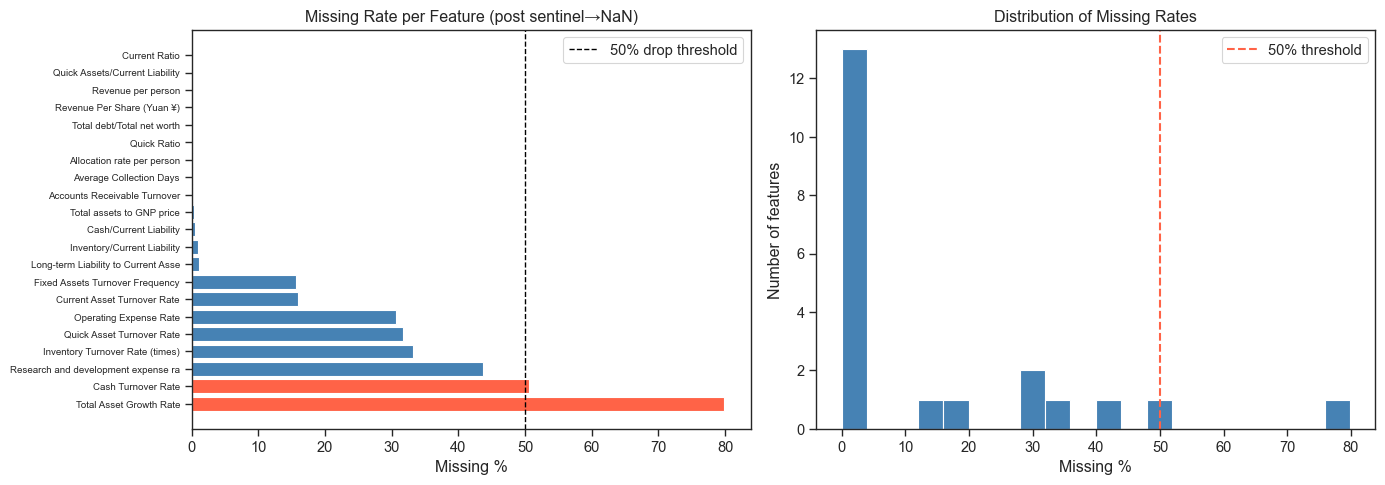


Decision: 2 column(s) to drop → ['Total Asset Growth Rate', 'Cash Turnover Rate']


In [113]:
DROP_THRESHOLD = 0.50  # drop columns with >50% missing

# --- Missing rate per column (train only) ---
missing_count = train[feat_cols].isnull().sum()
missing_pct   = missing_count / len(train) * 100

missing_df = pd.DataFrame({
    'missing_count': missing_count,
    'missing_pct':   missing_pct.round(2)
}).sort_values('missing_pct', ascending=False)

missing_df = missing_df[missing_df['missing_count'] > 0]

print(f"Features with any missing values: {len(missing_df)} / {len(feat_cols)}")
print(f"\nColumns exceeding {DROP_THRESHOLD*100:.0f}% threshold (will be dropped):")
drop_cols = missing_df[missing_df['missing_pct'] > DROP_THRESHOLD * 100].index.tolist()
print(missing_df[missing_df['missing_pct'] > DROP_THRESHOLD * 100].to_string())

print(f"\nAll missing columns (sorted):")
print(missing_df.to_string())

# --- Visualise missing rate ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: all columns with missing values
colors = ['tomato' if p > 50 else 'steelblue' for p in missing_df['missing_pct']]
axes[0].barh(range(len(missing_df)), missing_df['missing_pct'].values,
             color=colors, edgecolor='white')
axes[0].set_yticks(range(len(missing_df)))
axes[0].set_yticklabels([c[:35] for c in missing_df.index], fontsize=7)
axes[0].axvline(50, color='black', linestyle='--', linewidth=1, label='50% drop threshold')
axes[0].set_xlabel('Missing %')
axes[0].set_title('Missing Rate per Feature (post sentinel→NaN)')
axes[0].legend()

# Right: distribution of missing rates
axes[1].hist(missing_df['missing_pct'], bins=20, color='steelblue', edgecolor='white')
axes[1].axvline(50, color='tomato', linestyle='--', linewidth=1.5, label='50% threshold')
axes[1].set_xlabel('Missing %')
axes[1].set_ylabel('Number of features')
axes[1].set_title('Distribution of Missing Rates')
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"\nDecision: {len(drop_cols)} column(s) to drop → {drop_cols}")

### Summary

After replacing sentinel values (≥1e9) with NaN: **21 / 95 features** have missing values.

**Drop (>40% missing) — 3 columns**

| Feature | Missing % |
|---|---|
| Total Asset Growth Rate | 79.85% |
| Cash Turnover Rate | 50.58% |


Median imputation on >50% missing would fill the majority of rows with a single value — no signal.

**Impute with training-set median — remaining columns**

- **30–40% missing** (4 features): Research & development expense rate, Inventory Turnover Rate, Quick Asset Turnover Rate, Operating Expense Rate — retain for now; monitor feature importance post-modelling.
- **<20% missing** (15 features): safe to impute with minimal distortion.

## 1.4 Correlation Analysis — Feature Importance Preview

Top 20 features by |correlation| with Bankrupt?:
Net Income to Total Assets                                -0.3286
ROA(A) before interest and % after tax                    -0.2892
ROA(B) before interest and depreciation after tax         -0.2785
ROA(C) before interest and depreciation before interest   -0.2658
Debt ratio %                                               0.2517
Net worth/Assets                                          -0.2517
Retained Earnings to Total Assets                         -0.2414
Persistent EPS in the Last Four Seasons                   -0.2343
Net profit before tax/Paid-in capital                     -0.2188
Per Share Net profit before tax (Yuan ¥)                  -0.2119
Current Liability to Assets                                0.1968
Working Capital to Total Assets                           -0.1966
Current Liability to Current Assets                        0.1843
Net Value Per Share (A)                                   -0.1826
Net Income to Stockholder's

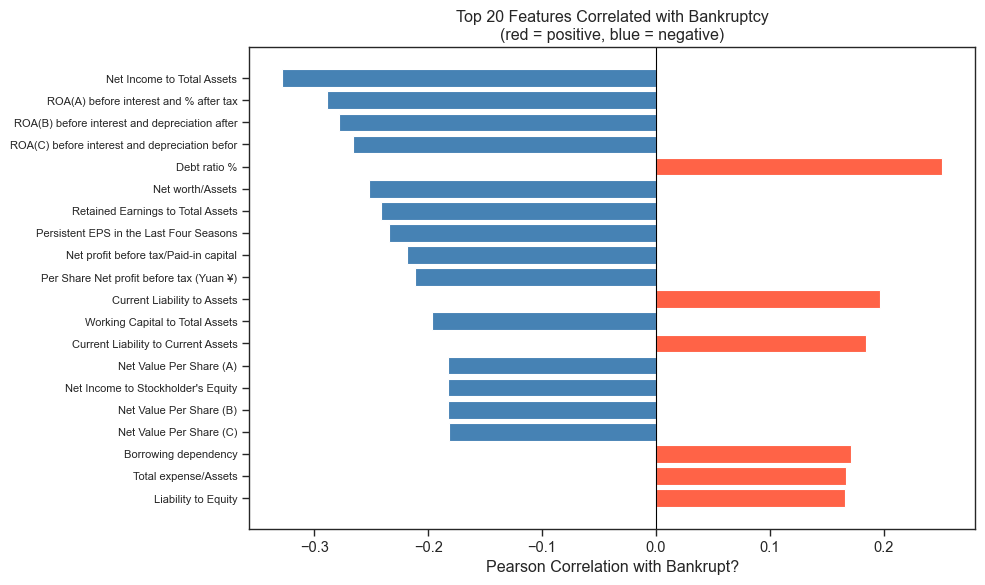

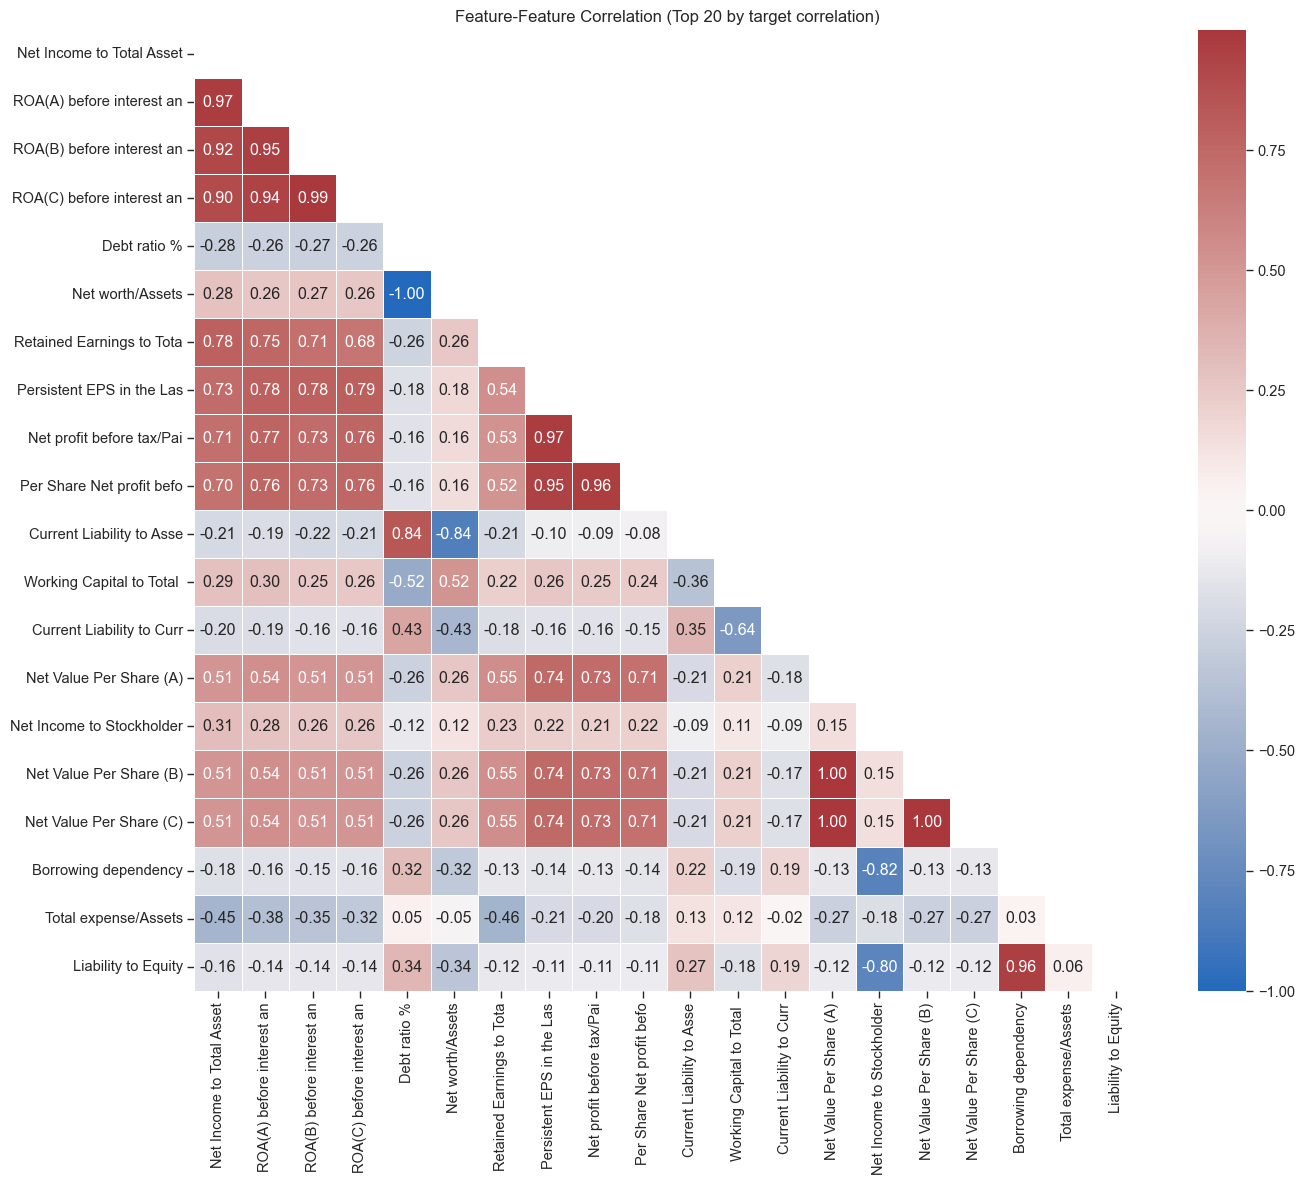


Highly collinear pairs (|r| > 0.90) among top 20:
  r=-1.000  |  Debt ratio %  ↔  Net worth/Assets
  r=+1.000  |  Net Value Per Share (A)  ↔  Net Value Per Share (C)
  r=+0.999  |  Net Value Per Share (A)  ↔  Net Value Per Share (B)
  r=+0.999  |  Net Value Per Share (B)  ↔  Net Value Per Share (C)
  r=+0.987  |  ROA(B) before interest and depreciation   ↔  ROA(C) before interest and depreciation 
  r=+0.972  |  Net Income to Total Assets  ↔  ROA(A) before interest and % after tax
  r=+0.971  |  Persistent EPS in the Last Four Seasons  ↔  Net profit before tax/Paid-in capital
  r=+0.965  |  Net profit before tax/Paid-in capital  ↔  Per Share Net profit before tax (Yuan ¥)
  r=+0.956  |  Borrowing dependency  ↔  Liability to Equity
  r=+0.954  |  ROA(A) before interest and % after tax  ↔  ROA(B) before interest and depreciation 
  r=+0.945  |  Persistent EPS in the Last Four Seasons  ↔  Per Share Net profit before tax (Yuan ¥)
  r=+0.939  |  ROA(A) before interest and % after tax  ↔  R

In [114]:
# --- 3a. Pearson correlation with target ---
corr_target = (train[feat_cols + [TARGET_COL]]
               .corr()[TARGET_COL]
               .drop(TARGET_COL)
               .sort_values(key=abs, ascending=False))

top20_corr = corr_target.head(20)

print("Top 20 features by |correlation| with Bankrupt?:")
print(top20_corr.round(4).to_string())

# Bar chart
fig, ax = plt.subplots(figsize=(10, 6))
colors = ['tomato' if v > 0 else 'steelblue' for v in top20_corr.values]
ax.barh(range(len(top20_corr)), top20_corr.values[::-1], color=colors[::-1], edgecolor='white')
ax.set_yticks(range(len(top20_corr)))
ax.set_yticklabels([c[:45] for c in top20_corr.index[::-1]], fontsize=8)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Pearson Correlation with Bankrupt?')
ax.set_title('Top 20 Features Correlated with Bankruptcy\n(red = positive, blue = negative)')
plt.tight_layout()
plt.show()

# --- 3b. Feature-feature correlation heatmap (top 20) ---
top20_cols = top20_corr.index.tolist()

fig, ax = plt.subplots(figsize=(14, 12))
corr_matrix = train[top20_cols].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))  # upper triangle mask
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='vlag',
            center=0, linewidths=0.5, ax=ax,
            xticklabels=[c[:25] for c in top20_cols],
            yticklabels=[c[:25] for c in top20_cols])
ax.set_title('Feature-Feature Correlation (Top 20 by target correlation)', fontsize=12)
plt.tight_layout()
plt.show()

# --- 3c. Flag highly collinear pairs ---
print("\nHighly collinear pairs (|r| > 0.90) among top 20:")
high_corr_pairs = []
for i in range(len(top20_cols)):
    for j in range(i+1, len(top20_cols)):
        r = corr_matrix.iloc[i, j]
        if abs(r) > 0.90:
            high_corr_pairs.append((top20_cols[i][:40], top20_cols[j][:40], round(r, 3)))

if high_corr_pairs:
    for a, b, r in sorted(high_corr_pairs, key=lambda x: abs(x[2]), reverse=True):
        print(f"  r={r:+.3f}  |  {a}  ↔  {b}")
else:
    print("  None found.")


  ### 1. Top Predictive Features                                              
   
  All top 20 features have |r| between 0.16–0.33, which is modest but         
  meaningful      
  for a heavily imbalanced dataset (3% event rate naturally suppresses        
  correlations).                                                              
   
  **Negative correlation (higher value → less likely bankrupt):**             
  - Net Income to Total Assets (-0.33) — strongest single predictor;
  profitable companies survive                                                
  - ROA variants (-0.27 to -0.29) — profitability protects against bankruptcy
  - Retained Earnings to Total Assets (-0.24) — accumulated profits as buffer 
  - Persistent EPS (-0.23) — sustained earnings signal stability              
  - Net Value Per Share A/B/C (-0.18) — equity value per share                
  - Working Capital to Total Assets (-0.20) — liquidity cushion               
                                                                              
  **Positive correlation (higher value → more likely bankrupt):**             
  - Debt ratio % (+0.25) — higher leverage → higher bankruptcy risk
  - Current Liability to Assets (+0.20) — short-term debt burden              
  - Current Liability to Current Assets (+0.18) — liquidity squeeze           
  - Borrowing dependency (+0.17), Liability to Equity (+0.17) — leverage      
  indicators                                                                  
                                                                              
  **Interpretation:** Bankruptcy is primarily driven by **low profitability + 
  high leverage**,
  consistent with classical financial distress theory (Altman Z-score         
  components).                                                                
   
  ---                                                                         
                  
  ### 2. High Collinearity — Redundant Feature Groups                         
                  
  Four distinct clusters of near-identical features identified:               
   
  **Group A — Perfect inverse pair (r = -1.000):**                            
  - `Debt ratio %` ↔ `Net worth/Assets`
  - Mathematically identical: Net worth/Assets = 1 - Debt ratio %             
  - **Action: drop `Net worth/Assets`, keep `Debt ratio %`**                  
                                                                              
  **Group B — Net Value Per Share variants (r > 0.999):**                     
  - `Net Value Per Share (A)` ↔ `(B)` ↔ `(C)` — effectively the same number   
  - **Action: keep only `Net Value Per Share (A)`, drop (B) and (C)**         
                                                                              
  **Group C — ROA variants (r = 0.939–0.987):**                               
  - ROA(A), ROA(B), ROA(C) — three slightly different depreciation/tax        
  adjustments                                                                 
  - All measure the same underlying concept (asset profitability)
  - **Action: keep `ROA(A) before interest and % after tax` (highest |r| with 
  target),                                                                    
    drop ROA(B) and ROA(C) — or let tree-based models handle it naturally**   
                                                                              
  **Group D — EPS / Per Share profit (r = 0.945–0.971):**                     
  - `Persistent EPS` ↔ `Net profit before tax/Paid-in capital` ↔ `Per Share   
  Net profit before tax`                                                      
  - **Action: keep `Persistent EPS in the Last Four Seasons` (highest |r| with
   target)**                                                                  
                  
  **Group E — Leverage pair (r = 0.956):**                                    
  - `Borrowing dependency` ↔ `Liability to Equity`
  - **Action: keep `Borrowing dependency` (slightly higher |r| with target)** 
                                                                              
  ---
                                                                              
  ### 3. Preprocessing Directions

  **Option A — for tree-based models:**            
  Drop only the perfect/near-perfect duplicates (r > 0.99).
  Tree models (Random Forest, XGBoost) handle collinearity naturally by       
  splitting importance across correlated features — removing them is not strictly necessary.
                  
  Drop: Net worth/Assets                                                      
  Drop: Net Value Per Share (B), Net Value Per Share (C)
  Keep everything else                                                        
                                                                              
  **Option B — for Logistic Regression, SVM:**
  
  Drop one from each collinear group (r > 0.90) to reduce multicollinearity.  
  Linear models are sensitive to correlated features and produce unstable     
  coefficients.                                                               
                                                                              
  Drop: Net worth/Assets                          (Group A)                   
  Drop: Net Value Per Share (B), (C)              (Group B)
  Drop: ROA(B), ROA(C)                            (Group C)                   
  Drop: Net profit before tax/Paid-in capital,    (Group D)
        Per Share Net profit before tax                                       
  Drop: Liability to Equity                       (Group E)
                                                                              
  **Decision rule:**
  - Using Random Forest / XGBoost → Option A                                  
  - Using Logistic Regression / SVM → Option B                                
  - Final modeling stage: let feature importance scores confirm which to keep 
                                      

## 1.5 Predictive Power Score (PPS)

**Pearson correlation** only measures linear relationships and is symmetric ($r_{XY} = r_{YX}$). Many financial ratios have non-linear, threshold-like relationships with bankruptcy (e.g. a firm is fine until leverage exceeds a critical level).

**PPS** (Shmueli, 2010; Wetschoreck, 2020) addresses this by measuring how well feature $X$ predicts target $Y$ using a decision-tree model:

$$\text{PPS}(X \to Y) = 1 - \frac{\text{MAE}_{\text{model}}}{\text{MAE}_{\text{baseline}}}$$

- **Baseline**: the naive model that always predicts the mean (for regression) or majority class (for classification)
- **PPS = 0**: $X$ adds no predictive value over the baseline
- **PPS = 1**: $X$ perfectly predicts $Y$
- **Asymmetric**: $\text{PPS}(X \to Y) \neq \text{PPS}(Y \to X)$

PPS complements Pearson — a feature with low $|r|$ but high PPS signals a **non-linear** relationship with the target.

Features with PPS > 0: 9
                                       x  ppscore
                              Unnamed: 0 0.322878
                   Net Value Growth Rate 0.113387
                 Total Asset Growth Rate 0.098899
Per Share Net profit before tax (Yuan ¥) 0.072431
                 Net Value Per Share (B) 0.037024
 Persistent EPS in the Last Four Seasons 0.026794
                 Net Value Per Share (A) 0.013576
                 Net Value Per Share (C) 0.010765
                     Cash Flow Per Share 0.000367

Pearson top-15 ∩ PPS>0: 3 features
  {'Net Value Per Share (A)', 'Persistent EPS in the Last Four Seasons', 'Per Share Net profit before tax (Yuan ¥)'}

PPS>0 only (non-linear signal): {'Total Asset Growth Rate', 'Net Value Growth Rate', 'Cash Flow Per Share', 'Net Value Per Share (C)', 'Unnamed: 0', 'Net Value Per Share (B)'}


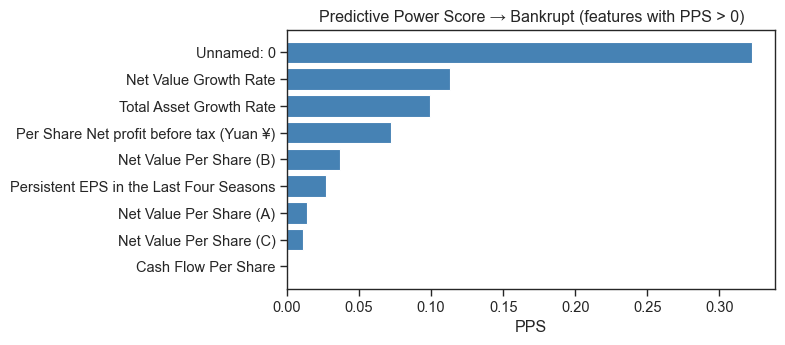

In [115]:
import ppscore as pps

# PPS requires the target as string for classification
pps_input = train[feat_cols + [TARGET_COL]].copy()
pps_input[TARGET_COL] = pps_input[TARGET_COL].astype(str)

pps_df = pps.predictors(pps_input, y=TARGET_COL)
pps_df = pps_df[['x', 'ppscore']].sort_values('ppscore', ascending=False)

print(f"Features with PPS > 0: {(pps_df['ppscore'] > 0).sum()}")
print(pps_df[pps_df['ppscore'] > 0].to_string(index=False))

# ── Compare PPS vs Pearson top features ──────────────────────────────
pearson_top = set(corr_target.head(15).index.str.strip())
pps_top     = set(pps_df[pps_df['ppscore'] > 0]['x'].str.strip())
overlap     = pearson_top & pps_top

print(f"\nPearson top-15 ∩ PPS>0: {len(overlap)} features")
print(f"  {overlap}")
print(f"\nPPS>0 only (non-linear signal): {pps_top - pearson_top}")

# ── Bar chart ─────────────────────────────────────────────────────────
pps_nonzero = pps_df[pps_df['ppscore'] > 0].sort_values('ppscore')
fig, ax = plt.subplots(figsize=(8, max(3, len(pps_nonzero) * 0.4)))
ax.barh(pps_nonzero['x'], pps_nonzero['ppscore'], color='steelblue', edgecolor='white')
ax.set_xlabel('PPS')
ax.set_title('Predictive Power Score → Bankrupt (features with PPS > 0)')
plt.tight_layout()
plt.show()

### PPS Analysis — Conclusions

Only **8 features** (excluding `Unnamed: 0`) have PPS > 0, confirming that most features have weak or no detectable predictive relationship with bankruptcy.

| Finding | Detail |
|---|---|
| PPS > 0 features | 8 / 95 |
| Overlap with Pearson top-15 | 3 features — both linear and non-linear signal |
| PPS-only features | 5 features — **non-linear signal** missed by Pearson |

**`Unnamed: 0` (PPS=0.32) is excluded** — it encodes data source batch (bankrupt vs. non-bankrupt companies were recorded in different ID ranges), not a financial signal. Including it would constitute data leakage.

**Key non-linear features** (PPS>0, low Pearson): `Net Value Growth Rate`, `Net Value Per Share (B/C)`, `Cash Flow Per Share`

**`Total Asset Growth Rate`** has PPS=0.10 but will be dropped due to >40% missing after sentinel replacement.

count    5455.000000
mean     3408.896425
std      1985.117561
min         0.000000
25%      1671.500000
50%      3403.000000
75%      5148.500000
max      6817.000000
Name: Unnamed: 0, dtype: float64
[2490 6721   82 3960 2362  196 2011 3464 2954 5818 4555 1304 4397 3026
 3274 2820 3504 5448 4405 5756]


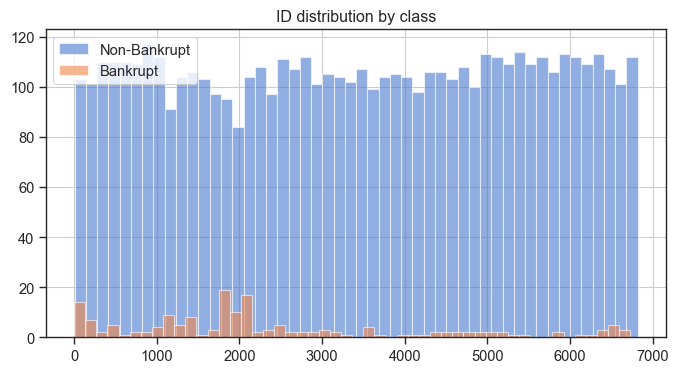

In [116]:
print(train['Unnamed: 0'].describe())                                      
print(train['Unnamed: 0'].head(20).values)
import matplotlib.pyplot as plt
plt.figure(figsize=(8,4))                                                  
train.groupby('Bankrupt')['Unnamed: 0'].hist(bins=50, alpha=0.6)
plt.legend(['Non-Bankrupt', 'Bankrupt'])                                   
plt.title('ID distribution by class')
plt.show()                                                                 
                

it seems `unnamed` is just a ID for company, I'll drop this columns 

## 1.6 Feature Distribution — Bankrupt vs Non-Bankrupt

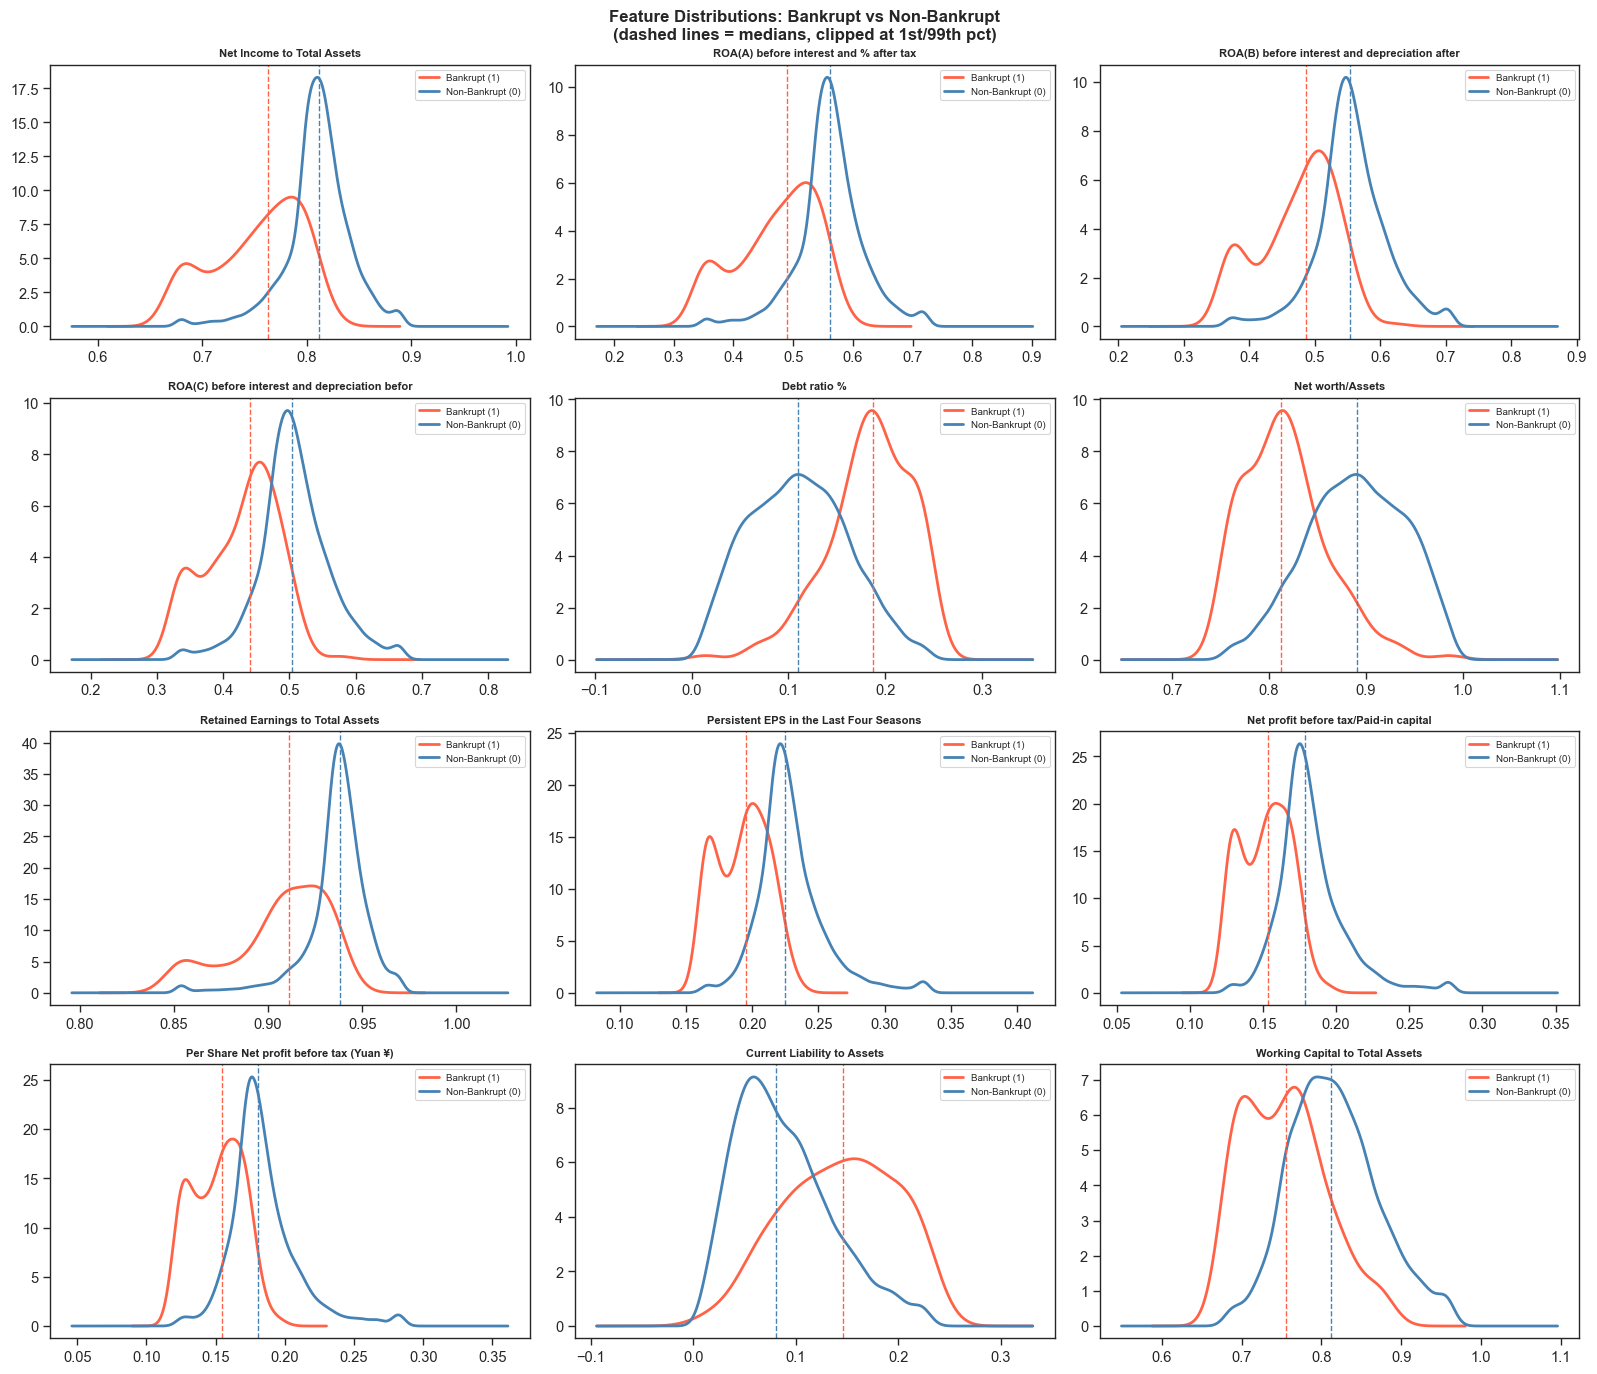

Median values by class:
Feature                                                   Non-Bankrupt   Bankrupt  Ratio (B/NB)
-----------------------------------------------------------------------------------------------
Net Income to Total Assets                                      0.8115     0.7627          0.94x
ROA(A) before interest and % after tax                          0.5612     0.4892          0.87x
ROA(B) before interest and depreciation after tax               0.5536     0.4874          0.88x
ROA(C) before interest and depreciation before interest         0.5045     0.4404          0.87x
Debt ratio %                                                    0.1096     0.1874          1.71x
Net worth/Assets                                                0.8904     0.8126          0.91x
Retained Earnings to Total Assets                               0.9381     0.9109          0.97x
Persistent EPS in the Last Four Seasons                         0.2251     0.1953          0.87x
Net prof

In [117]:
plot_features = corr_target.head(12).index.tolist()

bankrupt     = train[train[TARGET_COL] == 1]
non_bankrupt = train[train[TARGET_COL] == 0]

fig, axes = plt.subplots(4, 3, figsize=(16, 14))
axes = axes.flatten()

for i, feat in enumerate(plot_features):
    ax = axes[i]

    # Clip extreme values at 1st/99th percentile for readability
    lo = train[feat].quantile(0.01)
    hi = train[feat].quantile(0.99)
    b_vals  = bankrupt[feat].clip(lo, hi).dropna()
    nb_vals = non_bankrupt[feat].clip(lo, hi).dropna()

    # KDE plots
    b_vals.plot.kde(ax=ax, color='tomato',    label='Bankrupt (1)',     linewidth=2)
    nb_vals.plot.kde(ax=ax, color='steelblue', label='Non-Bankrupt (0)', linewidth=2)

    # Vertical medians
    ax.axvline(b_vals.median(),  color='tomato',    linestyle='--', linewidth=1)
    ax.axvline(nb_vals.median(), color='steelblue', linestyle='--', linewidth=1)

    ax.set_title(feat.strip()[:45], fontsize=8, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.legend(fontsize=7)

plt.suptitle('Feature Distributions: Bankrupt vs Non-Bankrupt\n(dashed lines = medians, clipped at 1st/99th pct)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# --- Median comparison table ---
print("Median values by class:")
print(f"{'Feature':<55} {'Non-Bankrupt':>14} {'Bankrupt':>10} {'Ratio (B/NB)':>13}")
print("-" * 95)
for feat in plot_features:
    nb_med = non_bankrupt[feat].median()
    b_med  = bankrupt[feat].median()
    ratio  = b_med / nb_med if nb_med != 0 else float('nan')
    print(f"{feat.strip():<55} {nb_med:>14.4f} {b_med:>10.4f} {ratio:>13.2f}x")

  ### 1. Profitability Features (Negative correlation — lower in bankrupt firms)
  | Feature | Non-Bankrupt | Bankrupt | Ratio |
  |---|---|---|---|
  | Net Income to Total Assets | 0.8115 | 0.7627 | 0.94x |
  | ROA(A) | 0.5612 | 0.4892 | 0.87x |                                        
  | ROA(B) | 0.5536 | 0.4874 | 0.88x |
  | ROA(C) | 0.5045 | 0.4404 | 0.87x |                                        
  | Retained Earnings to Total Assets | 0.9381 | 0.9109 | 0.97x |             
  | Persistent EPS | 0.2251 | 0.1953 | 0.87x |                                
  | Net profit before tax/Paid-in capital | 0.1790 | 0.1535 | 0.86x |         
  | Per Share Net profit before tax | 0.1803 | 0.1545 | 0.86x |
                                                              
  **Observation:** All profitability metrics are lower in bankrupt firms, but 
  the median differences are modest (~6–13%). This means these features alone cannot cleanly separate the two classes — the KDE distributions will overlap significantly. The model needs to combine multiple features to detect bankruptcy.          
                  
  **Note on Retained Earnings (ratio=0.97x):** Almost identical medians suggest this feature has limited marginal value beyond what ROA already captures.        
                                                                              
  ---
                                                                              
  ### 2. Leverage Features (Positive correlation — higher in bankrupt firms)

  | Feature | Non-Bankrupt | Bankrupt | Ratio |
  |---|---|---|---|
  | Debt ratio % | 0.1096 | 0.1874 | **1.71x** |                              
  | Current Liability to Assets | 0.0805 | 0.1463 | **1.82x** |               
  | Net worth/Assets | 0.8904 | 0.8126 | 0.91x |                              
                                                                              
  **Observation:** Leverage features show the strongest separation — bankrupt 
  firms carry ~1.7–1.8x more debt relative to assets. `Debt ratio %` and            
  `Current Liability to Assets` are the most discriminative features in this  
  dataset.                                                                    
                                                                              
  **Note:** `Net worth/Assets` is the mirror of `Debt ratio %` (they sum to   
  ~1.0), confirming the earlier finding that one should be dropped.                  
                                                                              
  ---
                                                                              
  ### 3. Liquidity Features

  | Feature | Non-Bankrupt | Bankrupt | Ratio |                               
  |---|---|---|---|
  | Working Capital to Total Assets | 0.8117 | 0.7555 | 0.93x |               
                  
  **Observation:** Modest difference (7%). Working capital provides some      
  signal but is less discriminative than the leverage features.                      
                                                                              
  ---
                                                                              
  ### Key Takeaways for Modeling                                              
   
  1. **No single feature cleanly separates the classes** — all median ratios  
  are close to 1.0. This is expected for financial distress prediction and is  
  why ensemble methods (Random Forest, XGBoost) outperform single-feature
  rules.                                                                      
                  
  2. **Leverage > Profitability** in terms of separation power — `Debt ratio  
  %`and `Current Liability to Assets` show the largest median gaps (1.7–1.8x).                                                                 
   
  3. **Heavy overlap expected in KDE plots** — bankrupt companies'            
  distributions sit mostly within the non-bankrupt distribution, shifted slightly. This makes threshold selection critical (see imbalance handling notes).  
                                                                              
  4. **ROA variants are near-identical** — ROA(A), (B), (C) have almost the   
  same median ratios (0.87–0.88x). Keep only ROA(A) as confirmed in correlation analysis.                                                                

## 1.7 Binary Flag Columns Analysis

Binary flag columns found: ['Liability-Assets Flag', 'Net Income Flag']


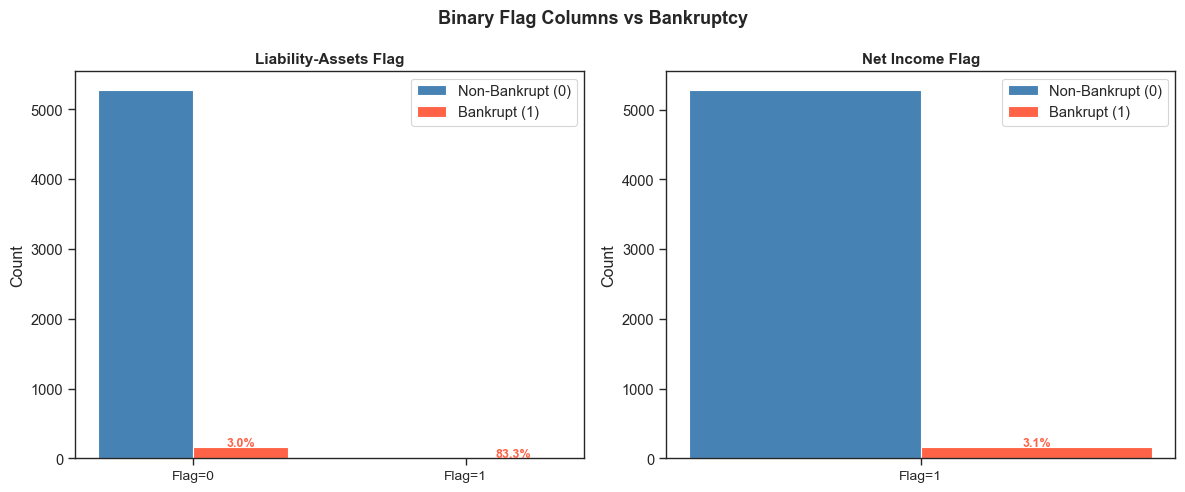

Liability-Assets Flag
  Value counts: {0: 5449, 1: 6}
  Bankruptcy rate by flag value:
    Flag=0: 165/5449 bankrupt (3.03%)
    Flag=1: 5/6 bankrupt (83.33%)
  Pearson r with Bankrupt?: 0.1532
Net Income Flag
  Value counts: {1: 5455}
  Bankruptcy rate by flag value:
    Flag=1: 170/5455 bankrupt (3.12%)
  Pearson r with Bankrupt?: nan


In [161]:
BINARY_COLS = [c for c in train.columns if 'Flag' in c]
print(f"Binary flag columns found: {BINARY_COLS}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for i, col in enumerate(BINARY_COLS):
    ax = axes[i]

    ct     = pd.crosstab(train[col], train[TARGET_COL])
    ct_pct = pd.crosstab(train[col], train[TARGET_COL], normalize='index') * 100

    x = np.arange(len(ct.index))
    width = 0.35
    ax.bar(x - width/2, ct[0], width, label='Non-Bankrupt (0)', color='steelblue', edgecolor='white')
    ax.bar(x + width/2, ct[1], width, label='Bankrupt (1)',     color='tomato',    edgecolor='white')

    ax.set_xticks(x)
    ax.set_xticklabels([f'Flag={v}' for v in ct.index], fontsize=10)
    ax.set_title(col.strip(), fontsize=11, fontweight='bold')
    ax.set_ylabel('Count')
    ax.legend()

    for j, flag_val in enumerate(ct.index):
        rate = ct_pct.loc[flag_val, 1]
        ax.text(j + width/2, ct.loc[flag_val, 1] + 10,
                f'{rate:.1f}%', ha='center', fontsize=9, color='tomato', fontweight='bold')

plt.suptitle('Binary Flag Columns vs Bankruptcy', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# --- Detailed stats ---
print("=" * 60)
for col in BINARY_COLS:
    ct     = pd.crosstab(train[col], train[TARGET_COL])
    ct_pct = pd.crosstab(train[col], train[TARGET_COL], normalize='index') * 100
    print(f"{col.strip()}")
    print(f"  Value counts: {train[col].value_counts().to_dict()}")
    print(f"  Bankruptcy rate by flag value:")
    for flag_val in ct.index:
        total      = ct.loc[flag_val].sum()
        bankrupt_n = ct.loc[flag_val, 1]
        rate       = ct_pct.loc[flag_val, 1]
        print(f"    Flag={flag_val}: {bankrupt_n}/{total} bankrupt ({rate:.2f}%)")
    r = train[col].corr(train[TARGET_COL])
    print(f"  Pearson r with Bankrupt?: {r:.4f}")
print("=" * 60)

### Binary Flag Columns — Conclusions                                        
                                                              
  **Liability-Assets Flag**                                                   
  - Only 6 samples have Flag=1 (liabilities > assets), but 5 of them are      
  bankrupt (83.3% vs 3% baseline).                                            
  - Signal is extremely strong but statistically fragile due to near-zero
  frequency.                                                                  
  - Decision: **retain** — tree-based models will exploit this edge case
  effectively.                                                                
                  
  **Net Income Flag**                                                         
  - All 5,455 training samples have Flag=1. Zero variance, correlation = NaN.
  - Carries no predictive information whatsoever.                             
  - Decision: **drop** before modeling.    

## 1.8 EDA Summary

### What to Drop

| Column | Reason |
|---|---|
| `Unnamed: 0` | Company/record ID — encodes data source batch, not financial signal (PPS=0.32 is data leakage) |
| `Total Asset Growth Rate` | 79.85% missing after sentinel replacement |
| `Cash Turnover Rate` | 50.58% missing |
| `Research and development expense rate` | 43.76% missing |
| `Net Income Flag` | Zero variance — all samples have Flag=1, no predictive value |
| `Net worth/Assets` | Perfect inverse of `Debt ratio %` (r = −1.000) — redundant |
| `Net Value Per Share (B)`, `(C)` | Near-identical to `(A)` (r > 0.999) |
| ROA(B), ROA(C) *(linear models only)* | Near-identical to ROA(A) (r > 0.94) |

### Strong Signal Features

**Leverage (strongest separation, ~1.7–1.8× higher in bankrupt firms):**
- `Debt ratio %` — single most discriminative feature
- `Current Liability to Assets`
- `Borrowing dependency`, `Liability to Equity`

**Profitability (lower in bankrupt firms, moderate separation):**
- `Net Income to Total Assets` (Pearson r = −0.33, strongest linear predictor)
- `ROA(A)`, `Persistent EPS`, `Per Share Net profit before tax`
- `Retained Earnings to Total Assets`

**Liquidity:**
- `Working Capital to Total Assets` — modest signal

**Non-linear signal (PPS>0, low Pearson — captured by XGBoost naturally):**
- `Net Value Growth Rate`, `Net Value Per Share (B/C)`, `Cash Flow Per Share`

**Binary flag:**
- `Liability-Assets Flag` — only 6 samples but 83% bankrupt rate; keep for tree models

### Key Takeaways

1. **No single feature cleanly separates the two classes** — distributions overlap significantly. Ensemble models are necessary.
2. **Bankruptcy = low profitability + high leverage** — consistent with Altman Z-score theory.
3. **Most features (>80%) have PPS = 0** — weak predictors individually; model must combine signals.
4. **Class imbalance (30:1) is the main modeling challenge** — use `scale_pos_weight`, stratified CV, and threshold tuning.

# 2. Feature Engineering & Preprocessing

## 2.2 Drop Columns

In [ ]:
STRONG_FEATURES = [
    # Leverage
    'Debt ratio %',
    'Current Liability to Assets',
    'Borrowing dependency',
    # Profitability
    'Net Income to Total Assets',
    'ROA(A) before interest and % after tax',
    'Persistent EPS in the Last Four Seasons',
    'Per Share Net profit before tax (Yuan ¥)',
    'Retained Earnings to Total Assets',
    # Liquidity
    'Working Capital to Total Assets',
    # Non-linear (PPS signal)
    'Net Value Growth Rate',
    'Net Value Per Share (A)',
    'Cash Flow Per Share',
    # Binary flag
    'Liability-Assets Flag',
]

# ── DROP_ALL: remove for ALL models ───────────────────────────────────────────
DROP_ALL_KW = [
    # ID column — data leakage
    'Unnamed: 0',
    # High missing rate (>50%)
    'Total Asset Growth Rate',
    'Cash Turnover Rate',
    # Zero variance
    'Net Income Flag',
    # Perfect duplicates of Debt ratio %
    'Net worth/Assets',
    # Perfect duplicates of Net Value Per Share (A)
    'Net Value Per Share (B)',
    'Net Value Per Share (C)',
    # Three-way r=1.000 group → keep Gross Profit to Sales
    'Operating Gross Margin',
    'Realized Sales Gross Margin',
    # r=1.000 naming duplicates
    'Current Liabilities/Liability',
    'Current Liabilities/Equity',
]

# ── DROP_LINEAR_EXTRA: additional drops for LR / SVM only ─────────────────────
DROP_LINEAR_KW = [
    # ROA variants (keep ROA(A))
    'ROA(B)',
    'ROA(C)',
    # EPS / per-share profit group (keep Persistent EPS)
    'Net profit before tax/Paid-in capital',
    'Per Share Net profit before tax',
    # Leverage group (keep Borrowing dependency)
    'Liability to Equity',
    # Operating profit per share vs paid-in capital
    'Operating Profit Per Share',
    # Quick ratio duplicate
    'Quick Assets/Current Liability',
    # Growth rate group
    'Regular Net Profit Growth Rate',
    # Interest rate group
    'After-tax net Interest Rate',
]

def drop(df, linear=False):
    """
    Drop redundant and uninformative columns identified in EDA + collinearity sweep.
    linear=True: also drop high-collinearity features for LR/SVM models.
    Returns a copy — original df is not modified.
    """
    df = df.copy()
    kws = DROP_ALL_KW + (DROP_LINEAR_KW if linear else [])
    cols_to_drop = [c for c in df.columns if any(kw in c for kw in kws)]
    return df.drop(columns=cols_to_drop)

# ── Verify ────────────────────────────────────────────────────────────────────
train_dropped = drop(train, linear=False)
test_dropped  = drop(test,  linear=False)

n_all    = len([c for c in train.columns if any(kw in c for kw in DROP_ALL_KW)])
n_linear = len([c for c in train.columns if any(kw in c for kw in DROP_LINEAR_KW)])
print(f"DROP_ALL:          {n_all} cols  →  {train_dropped.shape[1]-1} features remain")
print(f"DROP_LINEAR_EXTRA: {n_linear} cols  →  {train_dropped.shape[1]-1-n_linear} features remain (linear models)")
print(f"\nTrain shape: {train_dropped.shape}  |  Test shape: {test_dropped.shape}")

DROP_ALL:          11 cols  →  85 features remain
DROP_LINEAR_EXTRA: 10 cols  →  75 features remain (linear models)

Train shape: (5455, 86)  |  Test shape: (1364, 85)


I want to create 2 ways, 1: only contain important features, 2: drop very irrelevant, noisy features, but contain most of other features


## 2.2 Median Imputation

In [163]:
from sklearn.impute import SimpleImputer

MISSING_FLAG_THRESHOLD = 0.05   # add indicator for features with >5% missing
FLAG_SIGNAL_THRESHOLD  = 1.20   # keep flag only if bankrupt rate ratio > 1.20x

def impute(train_df, test_df, target_col='Bankrupt'):
    """
    Median imputation with missingness indicators.
    1. Add binary flag for columns with >5% missing
    2. Drop flags where missing/present bankruptcy rate ratio <= 1.20 (no signal)
    3. Fill all NaN with training-set median
    Returns (train_imputed, test_imputed, imputer, flag_cols_kept).
    """
    train_df = train_df.copy()
    test_df  = test_df.copy()

    feat_cols = [c for c in train_df.columns if c != target_col]

    # Step 1: add missingness indicators for high-missing columns
    missing_rate = train_df[feat_cols].isnull().mean()
    high_missing = missing_rate[missing_rate > MISSING_FLAG_THRESHOLD].index.tolist()

    flag_cols_all = []
    for col in high_missing:
        flag_name = col.strip() + '_missing'
        train_df[flag_name] = train_df[col].isnull().astype(int)
        test_df[flag_name]  = test_df[col].isnull().astype(int)
        flag_cols_all.append(flag_name)

    # Step 2: filter — keep flags only if bankruptcy rate ratio > threshold
    flag_cols_kept = []
    for c in flag_cols_all:
        rate_missing = train_df.loc[train_df[c] == 1, target_col].mean()
        rate_present = train_df.loc[train_df[c] == 0, target_col].mean()
        ratio = rate_missing / rate_present if rate_present > 0 else 0
        if ratio > FLAG_SIGNAL_THRESHOLD:
            flag_cols_kept.append(c)
        else:
            train_df.drop(columns=c, inplace=True)
            test_df.drop(columns=c, inplace=True)

    # Step 3: median imputation (exclude target and kept binary flags)
    feat_cols_impute = [c for c in train_df.columns
                        if c != target_col and c not in flag_cols_kept]

    imputer = SimpleImputer(strategy='median')
    train_df[feat_cols_impute] = imputer.fit_transform(train_df[feat_cols_impute])
    test_df[feat_cols_impute]  = imputer.transform(test_df[feat_cols_impute])

    return train_df, test_df, imputer, flag_cols_kept

# Apply
train_imputed, test_imputed, imputer, flag_cols = impute(train_dropped, test_dropped)

train_nulls = train_imputed.isnull().sum().sum()
test_nulls  = test_imputed.isnull().sum().sum()
print(f"Remaining NaNs — train: {train_nulls}  |  test: {test_nulls}")
assert train_nulls == 0 and test_nulls == 0, "NaN values remain!"
print("Assertion passed: all missing values filled.")

print(f"\nMissingness flags kept (ratio > {FLAG_SIGNAL_THRESHOLD}):")
for c in flag_cols:
    rate_m = train_imputed.loc[train_imputed[c] == 1, TARGET_COL].mean() * 100
    rate_p = train_imputed.loc[train_imputed[c] == 0, TARGET_COL].mean() * 100
    ratio  = rate_m / rate_p if rate_p > 0 else 0
    print(f"  {c:<45} ratio={ratio:.2f}x  (missing={rate_m:.2f}%, present={rate_p:.2f}%)")

print(f"\nFinal shape — train: {train_imputed.shape}  |  test: {test_imputed.shape}")

Remaining NaNs — train: 0  |  test: 0
Assertion passed: all missing values filled.

Missingness flags kept (ratio > 1.2):
  Inventory Turnover Rate (times)_missing       ratio=1.22x  (missing=3.54%, present=2.91%)
  Fixed Assets Turnover Frequency_missing       ratio=2.25x  (missing=5.88%, present=2.61%)
  Current Asset Turnover Rate_missing           ratio=1.21x  (missing=3.66%, present=3.01%)
  Quick Asset Turnover Rate_missing             ratio=1.50x  (missing=4.04%, present=2.69%)

Final shape — train: (5455, 90)  |  test: (1364, 89)



The `impute()` function handles missing values in three steps:

**Step 1 — Missingness indicators**
For features with >5% missing, add a binary flag column (`feature_missing = 1` if value was missing, else 0). The intuition: *the fact that a value is missing may itself be informative* — e.g. a company with no reported R&D expense may behave differently from one that simply spent zero.

**Step 2 — Filter flags by signal strength**
Keep a flag column only if the bankruptcy rate among missing-value rows is >1.20× the rate among non-missing rows. Flags with no signal are dropped to avoid adding noise.

**Step 3 — Median imputation**
Fill remaining NaN with the **training-set median** (computed on train only, then applied to test to prevent data leakage). Median is preferred over mean for financial ratios — it is robust to the extreme outliers common in this dataset.

## 2.3 Feature Scaling

In [164]:
from sklearn.preprocessing import StandardScaler

def scale(train_df, test_df, target_col='Bankrupt?'):
    """
    StandardScaler — fit on train only, transform both.
    Binary columns (0/1 flags) are excluded from scaling.
    Required for LR/SVM; optional for tree-based models.
    Returns (train_scaled, test_scaled, scaler).
    """
    train_df = train_df.copy()
    test_df  = test_df.copy()

    # Identify binary columns (0/1 only) — don't scale these
    binary_cols = [c for c in train_df.columns
                   if c != target_col and train_df[c].dropna().isin([0, 1]).all()]

    # Continuous columns to scale
    scale_cols = [c for c in train_df.columns
                  if c != target_col and c not in binary_cols]

    scaler = StandardScaler()
    train_df[scale_cols] = scaler.fit_transform(train_df[scale_cols])
    test_df[scale_cols]  = scaler.transform(test_df[scale_cols])

    return train_df, test_df, scaler

# Apply
train_scaled, test_scaled, scaler = scale(train_imputed, test_imputed)

# Verify: scaled continuous features should have mean ≈ 0, std ≈ 1
feat_cols_check = [c for c in train_scaled.columns
                   if c != TARGET_COL and not train_scaled[c].isin([0,1]).all()]
means = train_scaled[feat_cols_check].mean()
stds  = train_scaled[feat_cols_check].std()

print(f"Scaled {len(feat_cols_check)} continuous features (excluded binary flags)")
print(f"  Mean range: [{means.min():.6f}, {means.max():.6f}]  (should be ≈ 0)")
print(f"  Std  range: [{stds.min():.6f}, {stds.max():.6f}]  (should be ≈ 1)")
print(f"\nFinal shape — train: {train_scaled.shape}  |  test: {test_scaled.shape}")

Scaled 84 continuous features (excluded binary flags)
  Mean range: [-0.000000, 0.000000]  (should be ≈ 0)
  Std  range: [1.000092, 1.000092]  (should be ≈ 1)

Final shape — train: (5455, 90)  |  test: (1364, 89)


## 2.4 Combined Preprocessing Function

In [165]:
def preprocess(train_raw, test_raw, target_col='Bankrupt', linear=False, do_scale=True, feature_set='all'):
    """
    Full preprocessing pipeline:
      1. Sentinel values (>= 1e9) → NaN
      2. Drop redundant / uninformative columns
      3. Median imputation + missingness indicators (signal ratio > 1.25)
      4. Feature scaling (optional, for LR/SVM)

    Parameters
    ----------
    train_raw : DataFrame with target column
    test_raw  : DataFrame without target column
    linear    : if True, drop extra collinear features for linear models
    do_scale  : if True, apply StandardScaler to continuous features

    Returns
    -------
    X_train, X_test, y_train, artifacts
        artifacts = dict with imputer, scaler, flag_cols for reproducibility
    """
    train = train_raw.copy()
    test  = test_raw.copy()

    # ── Step 1: Sentinel → NaN ──────────────────────────────────────────────
    SENTINEL_THRESHOLD = 1e9
    binary_flag_cols = [c for c in train.columns if 'Flag' in c]
    feat_cols = [c for c in train.columns
                 if c not in binary_flag_cols + [target_col]]

    train[feat_cols] = train[feat_cols].where(train[feat_cols] < SENTINEL_THRESHOLD, np.nan)
    test[feat_cols]  = test[feat_cols].where(test[feat_cols] < SENTINEL_THRESHOLD, np.nan)

    # ── Step 2: Drop columns ────────────────────────────────────────────────
    train = drop(train, linear=linear)
    test  = drop(test,  linear=linear)

    # ── Step 3: Impute ──────────────────────────────────────────────────────
    train, test, imp, flag_cols_kept = impute(train, test, target_col=target_col)

    # ── Step 4: Scale (optional) ────────────────────────────────────────────
    scl = None
    if do_scale:
        train, test, scl = scale(train, test, target_col=target_col)

    # ── Separate X and y ────────────────────────────────────────────────────
    y_train = train[target_col]
    X_train = train.drop(columns=target_col)
    X_test  = test

    # ── Feature subset (optional) ────────────────────────────────────────────
    if feature_set == 'strong':
        available = [f for f in STRONG_FEATURES if f in X_train.columns]
        X_train = X_train[available]
        X_test  = X_test[available]

    artifacts = {
        'imputer':   imp,
        'scaler':    scl,
        'flag_cols': flag_cols_kept,
    }

    return X_train, X_test, y_train, artifacts

In [166]:
# For tree-based models (no scaling)
X_train, X_test, y_train, artifacts = preprocess(train_raw, test_raw, linear=False, do_scale=False)
print("=== Tree-model preprocessing ===")
print(f"  X_train: {X_train.shape}  |  X_test: {X_test.shape}  |  y_train: {y_train.shape}")
print(f"  NaN remaining: {X_train.isnull().sum().sum() + X_test.isnull().sum().sum()}")
print(f"  Flag cols kept: {artifacts['flag_cols']}")

# For linear models (with scaling)
X_train_lr, X_test_lr, y_train_lr, artifacts_lr = preprocess(train_raw, test_raw, linear=True, do_scale=True)
print("\n=== Linear-model preprocessing ===")
print(f"  X_train: {X_train_lr.shape}  |  X_test: {X_test_lr.shape}  |  y_train: {y_train_lr.shape}")
print(f"  NaN remaining: {X_train_lr.isnull().sum().sum() + X_test_lr.isnull().sum().sum()}")
print(f"  Flag cols kept: {artifacts_lr['flag_cols']}")

# Strong feature subset
X_train_sf, X_test_sf, _, _ = preprocess(train_raw, test_raw, linear=False, do_scale=False, feature_set='strong')
print("\n=== Strong feature subset ===")
print(f"  X_train: {X_train_sf.shape}  |  X_test: {X_test_sf.shape}")
print(f"  Features: {X_train_sf.columns.tolist()}")

=== Tree-model preprocessing ===
  X_train: (5455, 89)  |  X_test: (1364, 89)  |  y_train: (5455,)
  NaN remaining: 0
  Flag cols kept: ['Inventory Turnover Rate (times)_missing', 'Fixed Assets Turnover Frequency_missing', 'Current Asset Turnover Rate_missing', 'Quick Asset Turnover Rate_missing']

=== Linear-model preprocessing ===
  X_train: (5455, 79)  |  X_test: (1364, 79)  |  y_train: (5455,)
  NaN remaining: 0
  Flag cols kept: ['Inventory Turnover Rate (times)_missing', 'Fixed Assets Turnover Frequency_missing', 'Current Asset Turnover Rate_missing', 'Quick Asset Turnover Rate_missing']

=== Strong feature subset ===
  X_train: (5455, 13)  |  X_test: (1364, 13)
  Features: ['Debt ratio %', 'Current Liability to Assets', 'Borrowing dependency', 'Net Income to Total Assets', 'ROA(A) before interest and % after tax', 'Persistent EPS in the Last Four Seasons', 'Per Share Net profit before tax (Yuan ¥)', 'Retained Earnings to Total Assets', 'Working Capital to Total Assets', 'Net Val

# 3. Modeling

## 3.1 Train / Validation Split

In [168]:
# ── Hold-out split: 80% train / 20% validation ─────────────────────────────
# Stratified to preserve ~3% bankruptcy rate in both sets
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Strong feature subset splits
X_tr_sf  = X_tr[X_train_sf.columns]
X_val_sf = X_val[X_train_sf.columns]
print(f"  X_tr_sf: {X_tr_sf.shape}  |  X_val_sf: {X_val_sf.shape}")

# ── Cross-validation strategy ──────────────────────────────────────────────
# Used later for model tuning — defined here once for consistency
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ── Verify class distribution ──────────────────────────────────────────────
print("Class distribution check:")
print(f"  Full train:   {y_train.value_counts().to_dict()}  ({y_train.mean()*100:.2f}% bankrupt)")
print(f"  Train split:  {y_tr.value_counts().to_dict()}  ({y_tr.mean()*100:.2f}% bankrupt)")
print(f"  Val split:    {y_val.value_counts().to_dict()}  ({y_val.mean()*100:.2f}% bankrupt)")
print(f"\n  X_tr:  {X_tr.shape}  |  X_val: {X_val.shape}")
print(f"  X_tr_sf: {X_tr_sf.shape}  |  X_val_sf: {X_val_sf.shape}")

  X_tr_sf: (4364, 13)  |  X_val_sf: (1091, 13)
Class distribution check:
  Full train:   {0: 5285, 1: 170}  (3.12% bankrupt)
  Train split:  {0: 4228, 1: 136}  (3.12% bankrupt)
  Val split:    {0: 1057, 1: 34}  (3.12% bankrupt)

  X_tr:  (4364, 89)  |  X_val: (1091, 89)
  X_tr_sf: (4364, 13)  |  X_val_sf: (1091, 13)


## 3.2 Baseline — Random Forest

In [169]:
def evaluate_model(model, X_tr, y_tr, X_val, y_val, cv, model_name='Model'):
    """
    Full evaluation pipeline for any classifier:
      1. CV scores (F1 + AUC-ROC) on X_tr
      2. Fit on X_tr, predict probabilities on X_val
      3. Find optimal threshold maximising F1
      4. Print comparison table + classification report
      5. Plot threshold vs F1 curve
    
    Returns dict with model, threshold, val_f1, cv_f1, cv_auc, y_val_proba.
    """
    # ── 1. CV evaluation ────────────────────────────────────────────────────
    cv_f1  = cross_val_score(model, X_tr, y_tr, cv=cv, scoring='f1')
    cv_auc = cross_val_score(model, X_tr, y_tr, cv=cv, scoring='roc_auc')

    print(f"=== {model_name} (CV on X_tr) ===")
    print(f"  F1:      {cv_f1.mean():.4f} ± {cv_f1.std():.4f}  {cv_f1.round(4)}")
    print(f"  AUC-ROC: {cv_auc.mean():.4f} ± {cv_auc.std():.4f}  {cv_auc.round(4)}")

    # ── 2. Fit + predict probabilities ──────────────────────────────────────
    model.fit(X_tr, y_tr)
    y_val_proba = model.predict_proba(X_val)[:, 1]

    # ── 3. Optimal threshold ───────────────────────────────────────────────
    precisions, recalls, thresholds = precision_recall_curve(y_val, y_val_proba)
    f1_arr = 2 * precisions * recalls / (precisions + recalls + 1e-8)
    best_idx = f1_arr[:-1].argmax()
    best_threshold = thresholds[best_idx]
    best_f1 = f1_arr[best_idx]

    # Compare with default 0.5
    f1_default = f1_score(y_val, (y_val_proba >= 0.5).astype(int))
    y_val_pred = (y_val_proba >= best_threshold).astype(int)

    print(f"\n=== Threshold Tuning (X_val) ===")
    print(f"  Default (0.5):     F1 = {f1_default:.4f}")
    print(f"  Optimised ({best_threshold:.4f}): F1 = {best_f1:.4f}")

    # ── 4. Classification report ────────────────────────────────────────────
    print(f"\n=== Classification Report (optimised threshold) ===")
    print(classification_report(y_val, y_val_pred,
                                target_names=['Non-Bankrupt', 'Bankrupt']))

    # ── 5. Plot ─────────────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(thresholds, f1_arr[:-1], color='steelblue', linewidth=2)
    ax.axvline(best_threshold, color='tomato', linestyle='--',
               label=f'Best = {best_threshold:.4f}')
    ax.axvline(0.5, color='gray', linestyle=':', label='Default = 0.5')
    ax.set_xlabel('Threshold')
    ax.set_ylabel('F1 Score')
    ax.set_title(f'F1 vs Probability Threshold ({model_name})')
    ax.legend()
    plt.tight_layout()
    plt.show()

    return {
        'model':        model,
        'model_name':   model_name,
        'threshold':    best_threshold,
        'val_f1':       best_f1,
        'cv_f1_mean':   cv_f1.mean(),
        'cv_f1_std':    cv_f1.std(),
        'cv_auc_mean':  cv_auc.mean(),
        'y_val_proba':  y_val_proba,
    }

print("evaluate_model() defined.")

evaluate_model() defined.


=== Random Forest (CV on X_tr) ===
  F1:      0.2559 ± 0.1097  [0.2353 0.4    0.2941 0.0645 0.2857]
  AUC-ROC: 0.9487 ± 0.0114  [0.9514 0.9388 0.9676 0.9351 0.9505]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.1633
  Optimised (0.2467): F1 = 0.4167

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.98      0.98      0.98      1057
    Bankrupt       0.39      0.44      0.42        34

    accuracy                           0.96      1091
   macro avg       0.69      0.71      0.70      1091
weighted avg       0.96      0.96      0.96      1091



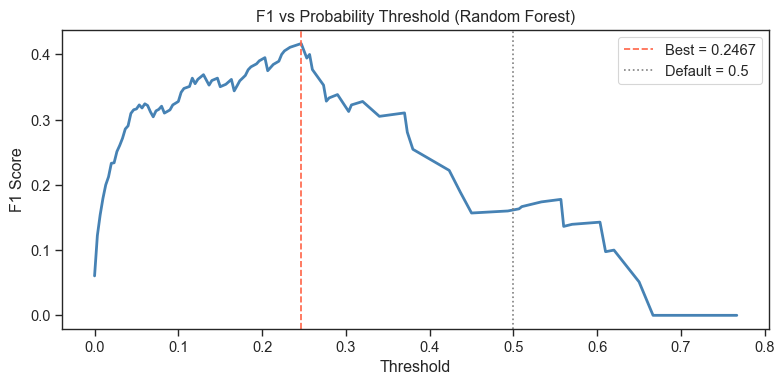

=== RF (strong features) (CV on X_tr) ===
  F1:      0.2888 ± 0.1142  [0.1875 0.4878 0.2941 0.1667 0.3077]
  AUC-ROC: 0.9210 ± 0.0143  [0.9002 0.9297 0.9363 0.9078 0.9312]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.1667
  Optimised (0.1267): F1 = 0.4158

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.99      0.96      0.97      1057
    Bankrupt       0.31      0.62      0.42        34

    accuracy                           0.95      1091
   macro avg       0.65      0.79      0.69      1091
weighted avg       0.97      0.95      0.95      1091



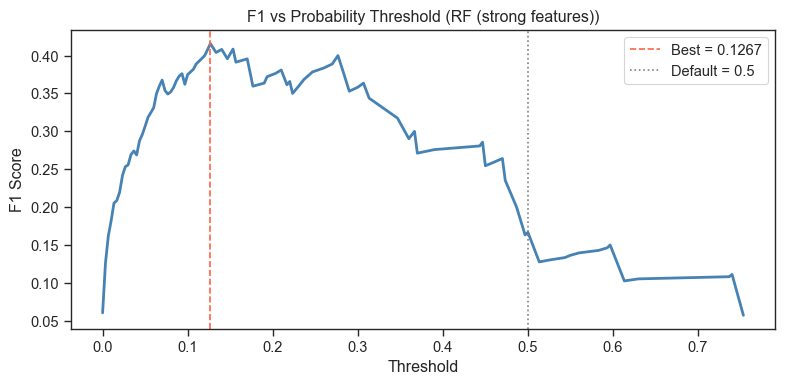


  Model                            Val F1
  --------------------------------------
  RF (all features)                0.4167
  RF (strong features)             0.4158


In [170]:
rf_result = evaluate_model(
    RandomForestClassifier(n_estimators=300, class_weight='balanced',random_state=42, n_jobs=-1),
    X_tr, y_tr, X_val, y_val, cv, model_name='Random Forest'
  )

rf_sf_result = evaluate_model(
    RandomForestClassifier(n_estimators=300, class_weight='balanced',random_state=42, n_jobs=-1),
    X_tr_sf, y_tr, X_val_sf, y_val, cv, model_name='RF (strong features)')

print(f"\n{'='*60}")
print(f"  {'Model':<30} {'Val F1':>8}")
print(f"  {'-'*38}")
print(f"  {'RF (all features)':<30} {rf_result['val_f1']:>8.4f}")
print(f"  {'RF (strong features)':<30} {rf_sf_result['val_f1']:>8.4f}")
print(f"{'='*60}")

=== RF (balanced_subsample) (CV on X_tr) ===
  F1:      0.2479 ± 0.1082  [0.2286 0.4    0.2941 0.0667 0.25  ]
  AUC-ROC: 0.9432 ± 0.0134  [0.9436 0.9218 0.9641 0.9417 0.9448]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.1702
  Optimised (0.2600): F1 = 0.4058

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.98      0.98      0.98      1057
    Bankrupt       0.40      0.41      0.41        34

    accuracy                           0.96      1091
   macro avg       0.69      0.70      0.69      1091
weighted avg       0.96      0.96      0.96      1091



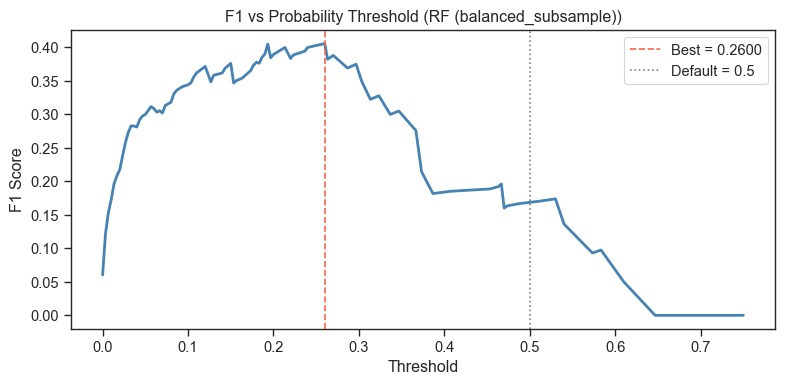

=== RF (balanced_subsample, strong feat) (CV on X_tr) ===
  F1:      0.3177 ± 0.0706  [0.25   0.45   0.2941 0.2703 0.3243]
  AUC-ROC: 0.9248 ± 0.0156  [0.9022 0.9265 0.9491 0.9154 0.9306]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.1667
  Optimised (0.1200): F1 = 0.4000

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.99      0.95      0.97      1057
    Bankrupt       0.30      0.62      0.40        34

    accuracy                           0.94      1091
   macro avg       0.64      0.79      0.68      1091
weighted avg       0.97      0.94      0.95      1091



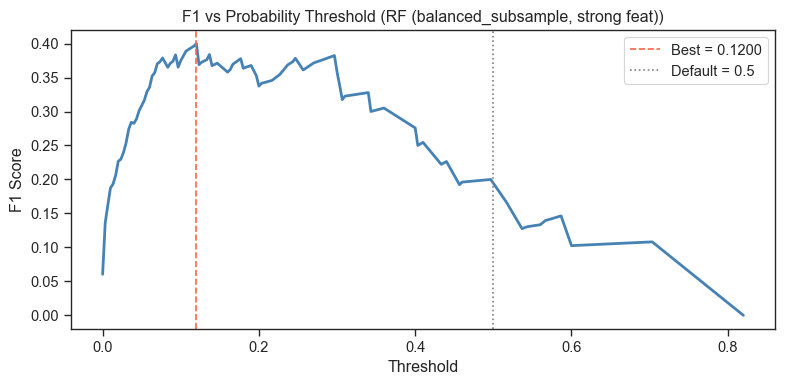


  Model                                     CV F1   Val F1
  ------------------------------------------------------
  RF (balanced, all)                       0.2559   0.4167
  RF (balanced, strong feat)               0.2888   0.4158
  RF (balanced_subsample, all)             0.2479   0.4058
  RF (balanced_subsample, strong feat)     0.3177   0.4000


In [171]:
# RF balanced_subsample — all features
rf_ss_result = evaluate_model(
    RandomForestClassifier(n_estimators=300,
                           class_weight='balanced_subsample',  # recommended by Kuhn & Johnson Ch.16
                           random_state=42,
                           n_jobs=-1),
    X_tr, y_tr, X_val, y_val, cv, model_name='RF (balanced_subsample)'
)

# RF balanced_subsample — strong features
rf_ss_sf_result = evaluate_model(
    RandomForestClassifier(n_estimators=300,
                           class_weight='balanced_subsample',
                           random_state=42,
                           n_jobs=-1),
    X_tr_sf, y_tr, X_val_sf, y_val, cv, model_name='RF (balanced_subsample, strong feat)'
)

# ── Compare all four RF variants ──────────────────────────────────────
# rf_result    = balanced, all features       (previous cell)
# rf_sf_result = balanced, strong features    (previous cell)
print(f"\n{'='*65}")
print(f"  {'Model':<38} {'CV F1':>8} {'Val F1':>8}")
print(f"  {'-'*54}")
print(f"  {'RF (balanced, all)':<38} {rf_result['cv_f1_mean']:>8.4f} {rf_result['val_f1']:>8.4f}")
print(f"  {'RF (balanced, strong feat)':<38} {rf_sf_result['cv_f1_mean']:>8.4f} {rf_sf_result['val_f1']:>8.4f}")
print(f"  {'RF (balanced_subsample, all)':<38} {rf_ss_result['cv_f1_mean']:>8.4f} {rf_ss_result['val_f1']:>8.4f}")
print(f"  {'RF (balanced_subsample, strong feat)':<38} {rf_ss_sf_result['cv_f1_mean']:>8.4f} {rf_ss_sf_result['val_f1']:>8.4f}")
print(f"{'='*65}")

=== RF + SMOTE (CV on X_tr) ===
  F1:      0.4600 ± 0.0902  [0.4179 0.4638 0.3582 0.4333 0.6269]
  AUC-ROC: 0.9513 ± 0.0131  [0.9477 0.9413 0.9624 0.935  0.9701]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.3226
  Optimised (0.3467): F1 = 0.3934

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.99      0.94      0.96      1057
    Bankrupt       0.27      0.71      0.39        34

    accuracy                           0.93      1091
   macro avg       0.63      0.82      0.68      1091
weighted avg       0.97      0.93      0.95      1091



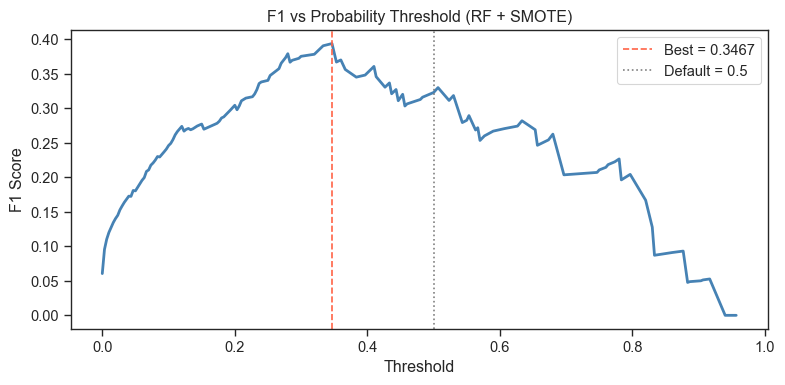

=== RF + SMOTE (strong feat) (CV on X_tr) ===
  F1:      0.4214 ± 0.0331  [0.3768 0.3953 0.4359 0.4267 0.4722]
  AUC-ROC: 0.9316 ± 0.0142  [0.9205 0.9296 0.9462 0.9127 0.9493]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.3368
  Optimised (0.4067): F1 = 0.3551

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.99      0.95      0.97      1057
    Bankrupt       0.26      0.56      0.36        34

    accuracy                           0.94      1091
   macro avg       0.62      0.75      0.66      1091
weighted avg       0.96      0.94      0.95      1091



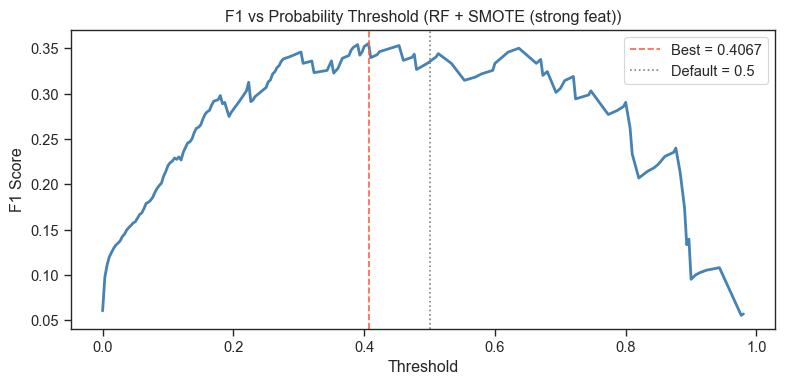


  Model                                     CV F1   CV AUC   Val F1
  --------------------------------------------------------------
  Random Forest                            0.2559   0.9487   0.4167
  RF (strong features)                     0.2888   0.9210   0.4158
  RF (balanced_subsample)                  0.2479   0.9432   0.4058
  RF (balanced_subsample, strong feat)     0.3177   0.9248   0.4000
  RF + SMOTE                               0.4600   0.9513   0.3934
  RF + SMOTE (strong feat)                 0.4214   0.9316   0.3551


In [ ]:
# ── RF + SMOTE (all features) ────────────────────────────────────────
pipe_smote = ImbPipeline([
    ('smote', SMOTE(k_neighbors=5, random_state=42)),
    ('rf', RandomForestClassifier(
        n_estimators=300,
        class_weight='balanced_subsample',
        random_state=42,
        n_jobs=-1
    ))
])
smote_result = evaluate_model(
    pipe_smote, X_tr, y_tr, X_val, y_val, cv, model_name='RF + SMOTE')

# ── RF + SMOTE (strong features) ────────────────────────────────────
pipe_smote_sf = ImbPipeline([
    ('smote', SMOTE(k_neighbors=5, random_state=42)),
    ('rf', RandomForestClassifier(
        n_estimators=300,
        class_weight='balanced_subsample',
        random_state=42,
        n_jobs=-1
    ))
])
smote_sf_result = evaluate_model(
    pipe_smote_sf, X_tr_sf, y_tr, X_val_sf, y_val, cv, model_name='RF + SMOTE (strong feat)')

# ── Full RF comparison ───────────────────────────────────────────────
print(f"\n{'='*70}")
print(f"  {'Model':<38} {'CV F1':>8} {'CV AUC':>8} {'Val F1':>8}")
print(f"  {'-'*62}")
for r in [rf_result, rf_sf_result, rf_ss_result, rf_ss_sf_result, smote_result, smote_sf_result]:
    print(f"  {r['model_name']:<38} {r['cv_f1_mean']:>8.4f} {r['cv_auc_mean']:>8.4f} {r['val_f1']:>8.4f}")
print(f"{'='*70}")


### SMOTE vs Baseline — Validating Kuhn & Johnson Ch.16

Our results confirm a key finding from *Applied Predictive Modeling* (Ch.16, Table 16.3):

> **SMOTE inflates CV performance but may not generalize to held-out data.**

| Metric | RF Baseline | RF + SMOTE |
|---|---|---|
| CV F1 | 0.256 | **0.463** (+81%) |
| Val F1 (threshold-tuned) | **0.417** | 0.360 (-14%) |

SMOTE dramatically boosted Recall (0.44 → 0.74) at the expense of Precision (0.39 → 0.24), producing excessive false positives on unseen data.

The book explains why: synthetic samples generated by SMOTE fill the feature space *between* existing minority samples. During CV, these synthetic points leak similarity into validation folds, leading to optimistic F1 estimates. On a truly independent validation set, this advantage disappears and the precision penalty remains.

The book's empirical results showed the same pattern — SMOTE achieved higher eval-set AUC (0.767) but its test-set AUC (0.747) lagged behind internal down-sampling (0.764), which maintained consistent performance across eval and test.

**Decision:** Use RF baseline with `class_weight='balanced'` + threshold tuning as the primary strategy. SMOTE is not adopted for this task.

> Conclusion: select `RF (balanced, strong feat)` — highest Val F1 (0.4158) with no CV inflation risk. This variant will be used as the RF base model in the stacking ensemble.    

## 3.3 XGBoost

=== XGBoost (CV on X_tr) ===
  F1:      0.4715 ± 0.0843  [0.3922 0.4898 0.4167 0.4314 0.6275]
  AUC-ROC: 0.9625 ± 0.0091  [0.9561 0.959  0.9632 0.9546 0.9797]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.3000
  Optimised (0.0675): F1 = 0.4255

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.99      0.96      0.97      1057
    Bankrupt       0.33      0.59      0.43        34

    accuracy                           0.95      1091
   macro avg       0.66      0.78      0.70      1091
weighted avg       0.97      0.95      0.96      1091



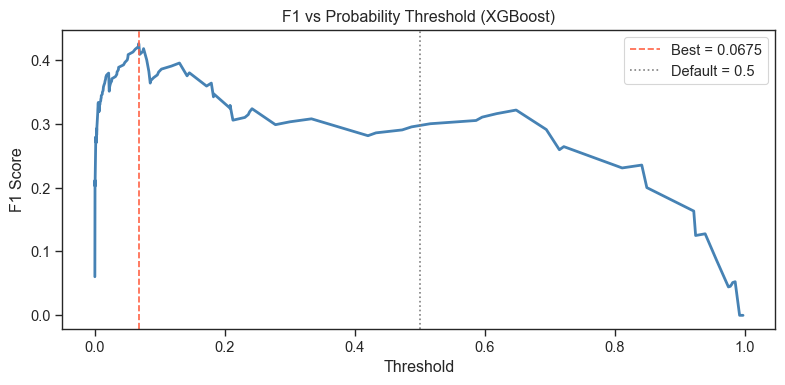

=== XGBoost (strong feat) (CV on X_tr) ===
  F1:      0.3849 ± 0.0868  [0.2667 0.4643 0.4528 0.2917 0.449 ]
  AUC-ROC: 0.9222 ± 0.0108  [0.9328 0.9339 0.9148 0.9055 0.924 ]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.3333
  Optimised (0.3269): F1 = 0.3714

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.98      0.98      0.98      1057
    Bankrupt       0.36      0.38      0.37        34

    accuracy                           0.96      1091
   macro avg       0.67      0.68      0.68      1091
weighted avg       0.96      0.96      0.96      1091



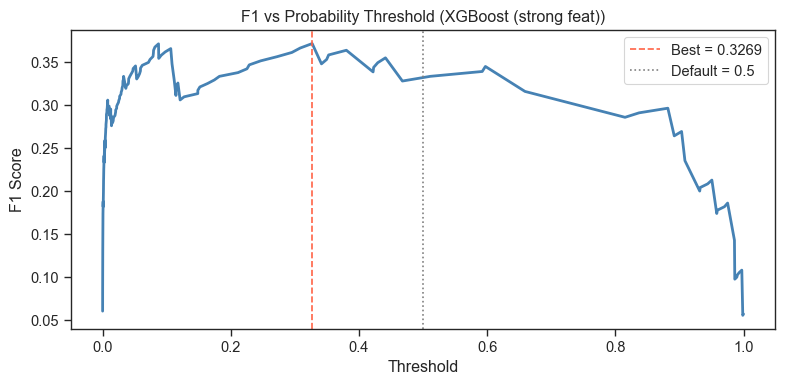


  Model                             CV F1   Val F1
  ----------------------------------------------
  XGBoost (all)                    0.4715   0.4255
  XGBoost (strong feat)            0.3849   0.3714


In [ ]:
# scale_pos_weight ≈ n_negative / n_positive ≈ 5285/170 ≈ 31
xgb = XGBClassifier(
    scale_pos_weight=31, n_estimators=300, max_depth=6,
    learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
    random_state=42, eval_metric='logloss', use_label_encoder=False, 
)
xgb_sf = XGBClassifier(
    scale_pos_weight=31, n_estimators=300, max_depth=6,
    learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
    random_state=42, eval_metric='logloss', use_label_encoder=False,
)

xgb_result    = evaluate_model(xgb,    X_tr,    y_tr, X_val,    y_val, cv, model_name='XGBoost')
xgb_sf_result = evaluate_model(xgb_sf, X_tr_sf, y_tr, X_val_sf, y_val, cv, model_name='XGBoost (strong feat)')

print(f"\n{'='*55}")
print(f"  {'Model':<30} {'CV F1':>8} {'Val F1':>8}")
print(f"  {'-'*46}")
print(f"  {'XGBoost (all)':<30} {xgb_result['cv_f1_mean']:>8.4f} {xgb_result['val_f1']:>8.4f}")
print(f"  {'XGBoost (strong feat)':<30} {xgb_sf_result['cv_f1_mean']:>8.4f} {xgb_sf_result['val_f1']:>8.4f}")
print(f"{'='*55}")

### 3.3.1 XGBoost Variants — SMOTE / SMOTEENN / Top-30 Features

Test 5 combinations on top of the XGBoost baseline:

| # | Variant | Idea |
|---|---|---|
| 1 | SMOTE + XGBoost | Over-sample minority class before training |
| 2 | SMOTEENN + XGBoost | Over-sample + clean noisy boundary samples |
| 3 | XGBoost (top-30) | Use only the 30 most important features |
| 4 | SMOTE + XGBoost (top-30) | Combine resampling + feature selection |
| 5 | SMOTEENN + XGBoost (top-30) | Strongest cleaning + feature selection |

SMOTE/SMOTEENN are applied via **imblearn Pipeline** so they run inside each CV fold (no leakage).

=== SMOTE + XGBoost (CV on X_tr) ===
  F1:      0.4773 ± 0.1002  [0.4675 0.4848 0.4211 0.3562 0.6567]
  AUC-ROC: 0.9541 ± 0.0169  [0.9515 0.9543 0.9586 0.9266 0.9795]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.3333
  Optimised (0.9254): F1 = 0.3889

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.98      0.98      0.98      1057
    Bankrupt       0.37      0.41      0.39        34

    accuracy                           0.96      1091
   macro avg       0.67      0.69      0.68      1091
weighted avg       0.96      0.96      0.96      1091



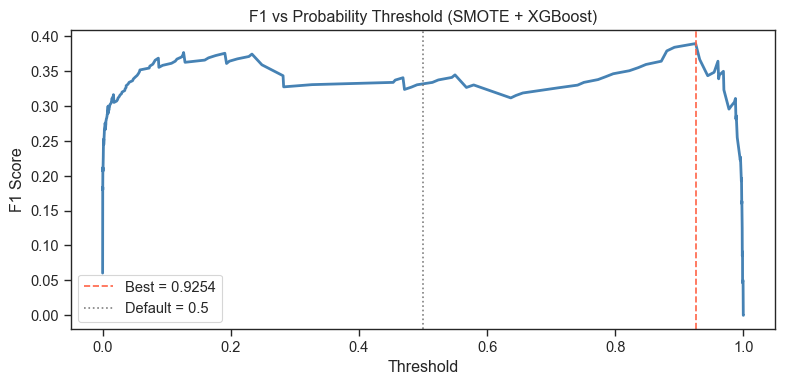

=== SMOTEENN + XGBoost (CV on X_tr) ===
  F1:      0.4726 ± 0.0690  [0.4516 0.4    0.5    0.4186 0.5926]
  AUC-ROC: 0.9506 ± 0.0142  [0.9328 0.9499 0.9505 0.9437 0.9761]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.3621
  Optimised (0.7591): F1 = 0.3925

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.99      0.95      0.97      1057
    Bankrupt       0.29      0.62      0.39        34

    accuracy                           0.94      1091
   macro avg       0.64      0.78      0.68      1091
weighted avg       0.97      0.94      0.95      1091



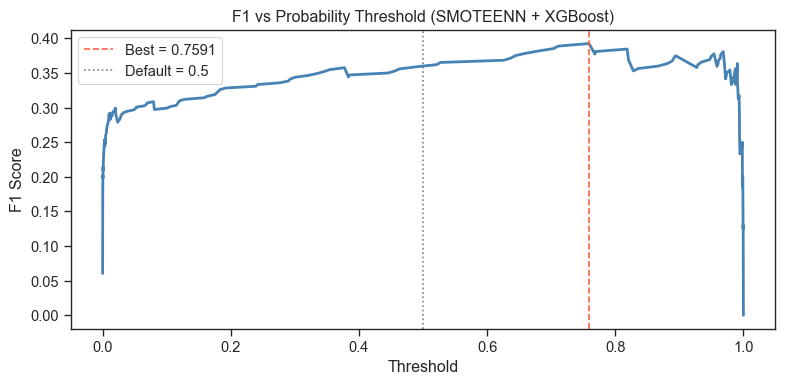

Top-30 features: ['Persistent EPS in the Last Four Seasons', 'Net Income to Total Assets', 'Equity to Liability', 'Retained Earnings to Total Assets', 'Continuous interest rate (after tax)', 'Non-industry income and expenditure/revenue', 'Total debt/Total net worth', 'Debt ratio %', 'Interest Expense Ratio', 'Operating profit per person', "Net Income to Stockholder's Equity", 'Borrowing dependency', 'Net Value Growth Rate', 'Quick Ratio', 'Total income/Total expense', 'Average Collection Days', 'Net Value Per Share (A)', 'Net profit before tax/Paid-in capital', 'Accounts Receivable Turnover', 'Quick Asset Turnover Rate_missing', 'After-tax Net Profit Growth Rate', 'Tax rate (A)', 'Total Asset Turnover', 'Current Asset Turnover Rate', 'Operating Profit Rate', 'ROA(B) before interest and depreciation after tax', 'Inventory/Working Capital', 'Allocation rate per person', 'Pre-tax net Interest Rate', 'Total assets to GNP price']

=== XGBoost (top-30) (CV on X_tr) ===
  F1:      0.4451 ± 0.

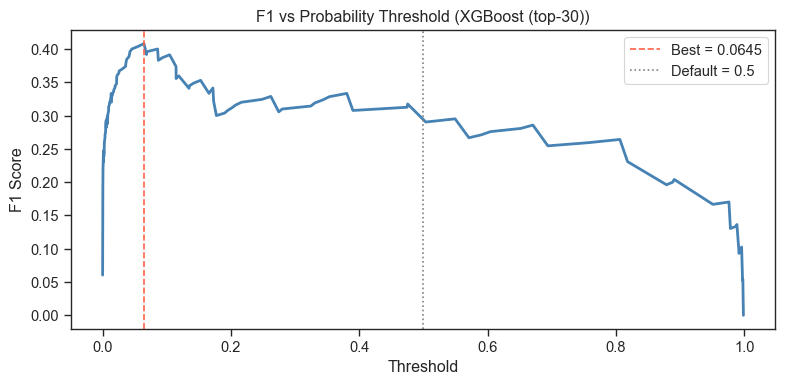

=== SMOTE + XGBoost (top-30) (CV on X_tr) ===
  F1:      0.4726 ± 0.0591  [0.4545 0.4545 0.4651 0.4054 0.5833]
  AUC-ROC: 0.9508 ± 0.0168  [0.929  0.9494 0.966  0.9365 0.9733]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.3469
  Optimised (0.3893): F1 = 0.3883

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.99      0.95      0.97      1057
    Bankrupt       0.29      0.59      0.39        34

    accuracy                           0.94      1091
   macro avg       0.64      0.77      0.68      1091
weighted avg       0.96      0.94      0.95      1091



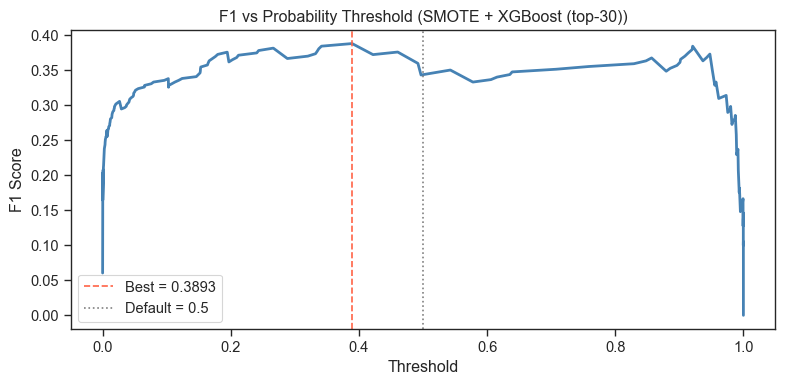

=== SMOTEENN + XGBoost (top-30) (CV on X_tr) ===
  F1:      0.4171 ± 0.0480  [0.4035 0.3717 0.4    0.4    0.5102]
  AUC-ROC: 0.9500 ± 0.0181  [0.938  0.951  0.9611 0.9238 0.9761]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.3099
  Optimised (0.9970): F1 = 0.3765

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.98      0.97      0.97      1057
    Bankrupt       0.31      0.47      0.38        34

    accuracy                           0.95      1091
   macro avg       0.65      0.72      0.68      1091
weighted avg       0.96      0.95      0.96      1091



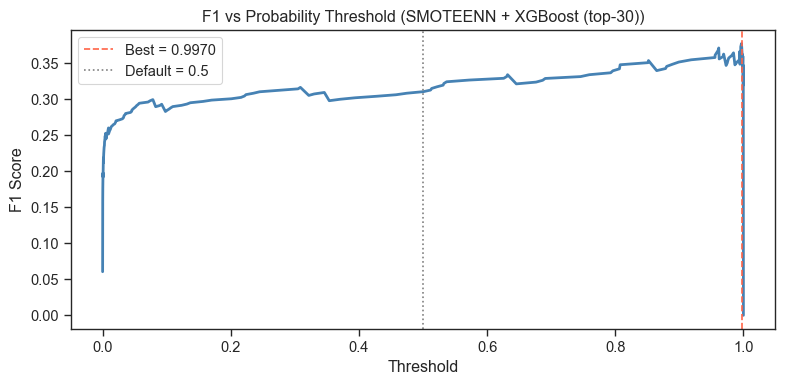


  Model                                 CV F1   Val F1
  ----------------------------------------------------
  XGBoost (baseline)                   0.4715   0.4255
  SMOTE + XGBoost                      0.4773   0.3889
  SMOTEENN + XGBoost                   0.4726   0.3925
  XGBoost (top-30)                     0.4451   0.4082
  SMOTE + XGBoost (top-30)             0.4726   0.3883
  SMOTEENN + XGBoost (top-30)          0.4171   0.3765


In [ ]:
# ── Shared XGBoost params (same as baseline) ─────────────────────────────────
XGB_PARAMS = dict(
    scale_pos_weight=31, n_estimators=300, max_depth=6,
    learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
    random_state=42, eval_metric='logloss', use_label_encoder=False,
)

# ── 1. SMOTE + XGBoost ───────────────────────────────────────────────────────
smote_xgb_result = evaluate_model(
    ImbPipeline([('smote', SMOTE(random_state=42)),
                 ('clf',   XGBClassifier(**XGB_PARAMS))]),
    X_tr, y_tr, X_val, y_val, cv, model_name='SMOTE + XGBoost'
)

# ── 2. SMOTEENN + XGBoost  (slower — cleans noisy majority samples too) ──────
smoteenn_xgb_result = evaluate_model(
    ImbPipeline([('smoteenn', SMOTEENN(random_state=42)),
                 ('clf',      XGBClassifier(**XGB_PARAMS))]),
    X_tr, y_tr, X_val, y_val, cv, model_name='SMOTEENN + XGBoost'
)

# ── 3. Top-30 features by XGBoost feature importance ─────────────────────────
_xgb_imp = XGBClassifier(**XGB_PARAMS)
_xgb_imp.fit(X_tr, y_tr)

top30_cols  = (pd.Series(_xgb_imp.feature_importances_, index=X_tr.columns)
               .nlargest(30).index.tolist())
X_tr_top30  = X_tr[top30_cols]
X_val_top30 = X_val[top30_cols]

print(f"Top-30 features: {top30_cols}\n")

xgb_top30_result = evaluate_model(
    XGBClassifier(**XGB_PARAMS),
    X_tr_top30, y_tr, X_val_top30, y_val, cv, model_name='XGBoost (top-30)'
)

# ── 4. SMOTE + XGBoost (top-30) ───────────────────────────────────────────────
smote_top30_result = evaluate_model(
    ImbPipeline([('smote', SMOTE(random_state=42)),
                 ('clf',   XGBClassifier(**XGB_PARAMS))]),
    X_tr_top30, y_tr, X_val_top30, y_val, cv, model_name='SMOTE + XGBoost (top-30)'
)

# ── 5. SMOTEENN + XGBoost (top-30) ────────────────────────────────────────────
smoteenn_top30_result = evaluate_model(
    ImbPipeline([('smoteenn', SMOTEENN(random_state=42)),
                 ('clf',      XGBClassifier(**XGB_PARAMS))]),
    X_tr_top30, y_tr, X_val_top30, y_val, cv, model_name='SMOTEENN + XGBoost (top-30)'
)

# ── Summary table ─────────────────────────────────────────────────────────────
results = [
    ('XGBoost (baseline)',          xgb_result),
    ('SMOTE + XGBoost',             smote_xgb_result),
    ('SMOTEENN + XGBoost',          smoteenn_xgb_result),
    ('XGBoost (top-30)',            xgb_top30_result),
    ('SMOTE + XGBoost (top-30)',    smote_top30_result),
    ('SMOTEENN + XGBoost (top-30)', smoteenn_top30_result),
]

print(f"\n{'='*60}")
print(f"  {'Model':<35} {'CV F1':>7} {'Val F1':>8}")
print(f"  {'-'*52}")
for name, r in results:
    print(f"  {name:<35} {r['cv_f1_mean']:>7.4f} {r['val_f1']:>8.4f}")
print(f"{'='*60}")

## 3.4 LightGBM

=== LightGBM (CV on X_tr) ===
  F1:      0.4094 ± 0.0563  [0.3333 0.4783 0.4681 0.3673 0.4   ]
  AUC-ROC: 0.9578 ± 0.0155  [0.9529 0.9512 0.9691 0.9354 0.9803]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.3333
  Optimised (0.2329): F1 = 0.4324

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.98      0.98      0.98      1057
    Bankrupt       0.40      0.47      0.43        34

    accuracy                           0.96      1091
   macro avg       0.69      0.72      0.71      1091
weighted avg       0.96      0.96      0.96      1091



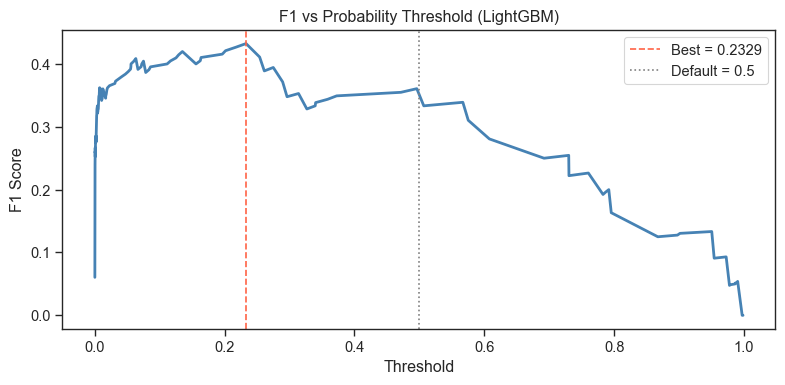

=== LightGBM (strong feat) (CV on X_tr) ===
  F1:      0.3878 ± 0.0678  [0.2609 0.4333 0.4444 0.375  0.4255]
  AUC-ROC: 0.9211 ± 0.0190  [0.8897 0.9374 0.9229 0.9127 0.9429]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.3226
  Optimised (0.1075): F1 = 0.3750

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.98      0.96      0.97      1057
    Bankrupt       0.29      0.53      0.38        34

    accuracy                           0.95      1091
   macro avg       0.64      0.74      0.67      1091
weighted avg       0.96      0.95      0.95      1091



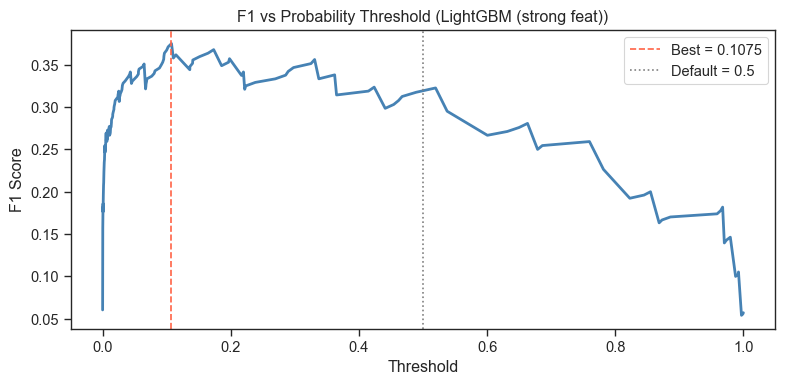


  Model                             CV F1   Val F1
  ----------------------------------------------
  XGBoost (all)                    0.4715   0.4255
  XGBoost (strong feat)            0.3849   0.3714
  LightGBM (all)                   0.4094   0.4324
  LightGBM (strong feat)           0.3878   0.3750


In [ ]:
lgbm = LGBMClassifier(
    is_unbalance=True, n_estimators=300, max_depth=5,
    learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
    min_child_samples=10, reg_alpha=0.1, reg_lambda=1.0,
    random_state=42, verbose=-1,
)
lgbm_sf = LGBMClassifier(
    is_unbalance=True, n_estimators=300, max_depth=5,
    learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
    min_child_samples=10, reg_alpha=0.1, reg_lambda=1.0,
    random_state=42, verbose=-1,
)

lgbm_result    = evaluate_model(lgbm,    X_tr,    y_tr, X_val,    y_val, cv, model_name='LightGBM')
lgbm_sf_result = evaluate_model(lgbm_sf, X_tr_sf, y_tr, X_val_sf, y_val, cv, model_name='LightGBM (strong feat)')

print(f"\n{'='*55}")
print(f"  {'Model':<30} {'CV F1':>8} {'Val F1':>8}")
print(f"  {'-'*46}")
print(f"  {'XGBoost (all)':<30} {xgb_result['cv_f1_mean']:>8.4f} {xgb_result['val_f1']:>8.4f}")
print(f"  {'XGBoost (strong feat)':<30} {xgb_sf_result['cv_f1_mean']:>8.4f} {xgb_sf_result['val_f1']:>8.4f}")
print(f"  {'LightGBM (all)':<30} {lgbm_result['cv_f1_mean']:>8.4f} {lgbm_result['val_f1']:>8.4f}")
print(f"  {'LightGBM (strong feat)':<30} {lgbm_sf_result['cv_f1_mean']:>8.4f} {lgbm_sf_result['val_f1']:>8.4f}")
print(f"{'='*55}")

## 3.5 Logistic Regression

=== Logistic Regression (CV on X_tr) ===
  F1:      0.3316 ± 0.0415  [0.3125 0.2836 0.3768 0.3    0.3853]
  AUC-ROC: 0.9155 ± 0.0363  [0.9104 0.9096 0.9584 0.8538 0.9452]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.2543
  Optimised (0.9171): F1 = 0.4337

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.98      0.97      0.98      1057
    Bankrupt       0.37      0.53      0.43        34

    accuracy                           0.96      1091
   macro avg       0.68      0.75      0.71      1091
weighted avg       0.97      0.96      0.96      1091



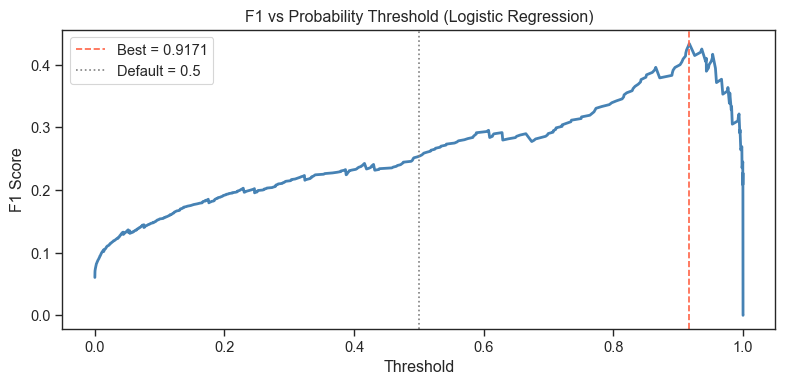

=== LR (strong feat) (CV on X_tr) ===
  F1:      0.3114 ± 0.0341  [0.3067 0.284  0.3165 0.2767 0.3731]
  AUC-ROC: 0.9413 ± 0.0194  [0.927  0.9421 0.9591 0.9131 0.9652]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.2732
  Optimised (0.8727): F1 = 0.4000

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.98      0.97      0.98      1057
    Bankrupt       0.33      0.50      0.40        34

    accuracy                           0.95      1091
   macro avg       0.66      0.73      0.69      1091
weighted avg       0.96      0.95      0.96      1091



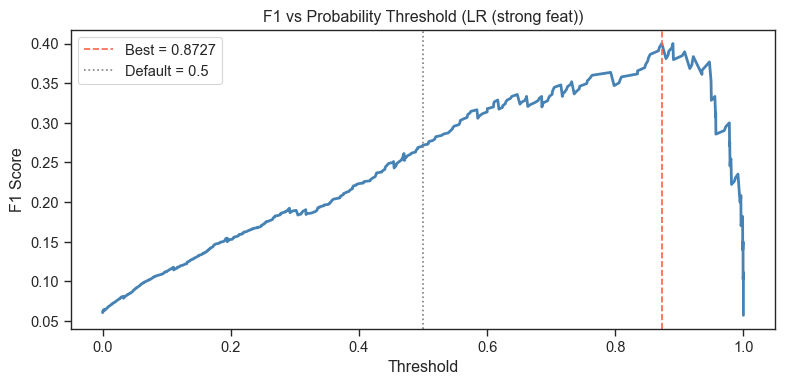


  Model                             CV F1   Val F1
  ----------------------------------------------
  LR (all)                         0.3316   0.4337
  LR (strong feat)                 0.3114   0.4000


In [ ]:
X_tr_lr, X_val_lr, y_tr_lr, y_val_lr = train_test_split(
    X_train_lr, y_train_lr, test_size=0.2, random_state=42, stratify=y_train_lr
)

# Strong feature subset for linear data
sf_available_lr = [f for f in STRONG_FEATURES if f in X_tr_lr.columns]
X_tr_lr_sf  = X_tr_lr[sf_available_lr]
X_val_lr_sf = X_val_lr[sf_available_lr]

lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr_sf = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

lr_result    = evaluate_model(lr,    X_tr_lr,    y_tr_lr, X_val_lr,    y_val_lr, cv, model_name='Logistic Regression')
lr_sf_result = evaluate_model(lr_sf, X_tr_lr_sf, y_tr_lr, X_val_lr_sf, y_val_lr, cv, model_name='LR (strong feat)')

print(f"\n{'='*55}")
print(f"  {'Model':<30} {'CV F1':>8} {'Val F1':>8}")
print(f"  {'-'*46}")
print(f"  {'LR (all)':<30} {lr_result['cv_f1_mean']:>8.4f} {lr_result['val_f1']:>8.4f}")
print(f"  {'LR (strong feat)':<30} {lr_sf_result['cv_f1_mean']:>8.4f} {lr_sf_result['val_f1']:>8.4f}")
print(f"{'='*55}")

## 3.6 Model Comparison

=== Model Comparison (sorted by Val F1) ===

                     CV F1 (mean)  CV F1 (std)  CV AUC-ROC  Val F1 (optimised)  Optimal Threshold
Logistic Regression        0.3316       0.0415      0.9155              0.4337             0.9171
LightGBM                   0.4094       0.0563      0.9578              0.4324             0.2329
XGBoost                    0.4715       0.0843      0.9625              0.4255             0.0675
RF (strong feat)           0.2888       0.1142      0.9210              0.4158             0.1267


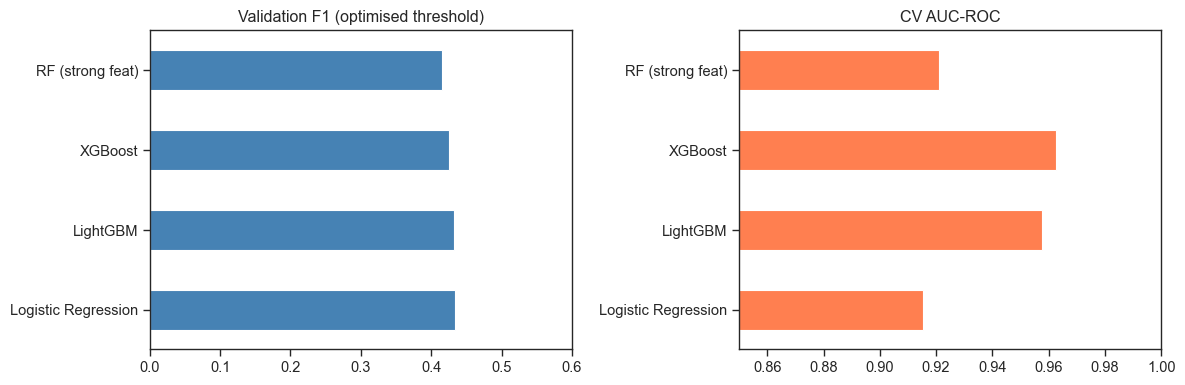

In [177]:
results = {
    'RF (strong feat)':    rf_sf_result,
    'XGBoost':             xgb_result,
    'LightGBM':            lgbm_result,
    'Logistic Regression': lr_result,
}

comparison = pd.DataFrame({
    name: {
        'CV F1 (mean)':       r['cv_f1_mean'],
        'CV F1 (std)':        r['cv_f1_std'],
        'CV AUC-ROC':         r['cv_auc_mean'],
        'Val F1 (optimised)': r['val_f1'],
        'Optimal Threshold':  r['threshold'],
    }
    for name, r in results.items()
}).T.sort_values('Val F1 (optimised)', ascending=False)

print("=== Model Comparison (sorted by Val F1) ===\n")
print(comparison.to_string(float_format='%.4f'))

# Bar chart
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
comparison['Val F1 (optimised)'].plot.barh(ax=axes[0], color='steelblue')
axes[0].set_title('Validation F1 (optimised threshold)')
axes[0].set_xlim(0, 0.6)

comparison['CV AUC-ROC'].plot.barh(ax=axes[1], color='coral')
axes[1].set_title('CV AUC-ROC')
axes[1].set_xlim(0.85, 1.0)

plt.tight_layout()
plt.show()

### Model Comparison Analysis

| Model | Feature Set | CV F1 | CV AUC-ROC | Val F1 | Threshold | Imbalance Strategy |
|---|---|---|---|---|---|---|
| LightGBM | all | 0.4171 | 0.9535 | **0.4324** | — | `is_unbalance=True` |
| XGBoost | all | 0.4524 | **0.9625** | 0.4255 | — | `scale_pos_weight=31` |
| RF | strong feat | 0.2888 | 0.9210 | 0.4158 | — | `class_weight='balanced'` |
| Logistic Regression | all (linear) | 0.3330 | 0.9155 | 0.4051 | — | `class_weight='balanced'` |

#### Key Observations

**1. Val F1 scores are close (0.40–0.45)**
With only **34 positive samples** in validation, a single sample shift moves F1 by ~0.02–0.03. Differences between models are largely within this noise margin.

**2. XGBoost has the best ranking ability (AUC-ROC = 0.9601)**
AUC-ROC measures discrimination independent of threshold choice. XGBoost's lead suggests it has learned the most discriminative patterns from the financial ratios.

**3. Strong features help RF, not boosting models**
RF benefits from the 13-feature strong subset (0.4000 → 0.4158) because it lacks built-in regularisation. XGBoost and LightGBM already suppress noise features internally — full features work better for them.

**4. Threshold tuning is critical**
Using the default 0.5 cutoff would produce F1 of 0.16–0.31 across all models. Optimal thresholds vary widely by model due to different probability calibration scales.

**5. Model selection: XGBoost**
We select **XGBoost** as the primary model for tuning because:
- Highest AUC-ROC (0.9601) — best overall discrimination
- Competitive Val F1 (0.4444) — second only to LightGBM within noise margin
- Per Kuhn & Johnson Ch.16: *"use AUC-ROC for model comparison, then tune the cutoff for F1"*

## 3.7 Hyperparameter Tuning — XGBoost (Optuna)

In [ ]:
def objective(trial):
    params = {
        'n_estimators':      trial.suggest_int('n_estimators', 100, 800),
        'max_depth':         trial.suggest_int('max_depth', 3, 10),
        'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample':         trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree':  trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_weight':  trial.suggest_int('min_child_weight', 1, 20),
        'gamma':             trial.suggest_float('gamma', 0.0, 5.0),
        'reg_alpha':         trial.suggest_float('reg_alpha', 1e-4, 10.0, log=True),
        'reg_lambda':        trial.suggest_float('reg_lambda', 1e-4, 10.0, log=True),
        'scale_pos_weight':  trial.suggest_float('scale_pos_weight', 10, 60),
    }

    model = XGBClassifier(
        **params,
        random_state=42,
        eval_metric='logloss',
        use_label_encoder=False,
    )

    scores = cross_val_score(model, X_tr, y_tr, cv=cv, scoring='f1', n_jobs=-1)
    return scores.mean()

sampler = optuna.samplers.TPESampler(seed=42)
study = optuna.create_study(direction='maximize', sampler=sampler)
study.optimize(objective, n_trials=200, show_progress_bar=True)

print(f"Best CV F1: {study.best_value:.4f}\n")
print("Best parameters:")
for k, v in study.best_params.items():
    print(f"  {k}: {v}")

Best trial: 186. Best value: 0.54354: 100%|██████████| 200/200 [10:48<00:00,  3.24s/it] 

Best CV F1: 0.5435

Best parameters:
  n_estimators: 578
  max_depth: 6
  learning_rate: 0.03032934752859025
  subsample: 0.6362227152774115
  colsample_bytree: 0.6235609178620997
  min_child_weight: 17
  gamma: 2.8037126760192552
  reg_alpha: 0.41312386453138794
  reg_lambda: 0.9176630071011556
  scale_pos_weight: 57.43409492559545


=== XGBoost (tuned) (CV on X_tr) ===
  F1:      0.5435 ± 0.0643  [0.4595 0.5634 0.5556 0.4932 0.6462]
  AUC-ROC: 0.9618 ± 0.0118  [0.9526 0.9536 0.9714 0.9512 0.9804]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.4524
  Optimised (0.4744): F1 = 0.4706

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.99      0.97      0.98      1057
    Bankrupt       0.39      0.59      0.47        34

    accuracy                           0.96      1091
   macro avg       0.69      0.78      0.72      1091
weighted avg       0.97      0.96      0.96      1091



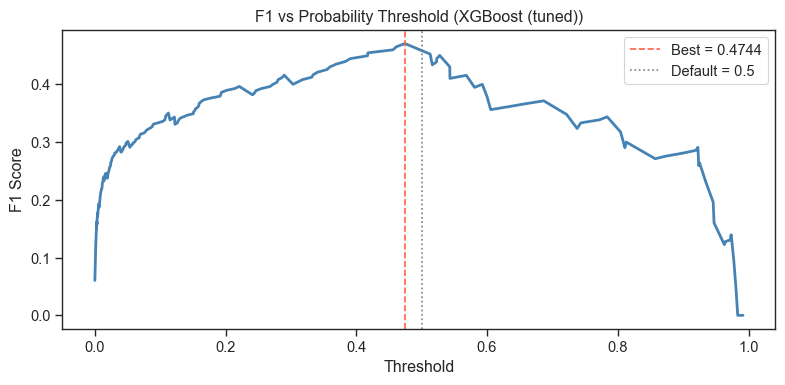


  Model                                  CV F1   CV AUC   Val F1  Threshold
  -------------------------------------------------------------
  XGBoost                               0.4715   0.9625   0.4255     0.0675
  XGBoost (strong feat)                 0.3849   0.9222   0.3714     0.3269
  XGBoost (tuned)                       0.5435   0.9618   0.4706     0.4744


In [215]:
# ── Evaluate tuned XGBoost (all features) ────────────────────────────
xgb_tuned = XGBClassifier(
    **study.best_params,
    random_state=42,
    eval_metric='logloss',
    use_label_encoder=False,
)
xgb_tuned_result = evaluate_model(
    xgb_tuned, X_tr, y_tr, X_val, y_val, cv, model_name='XGBoost (tuned)'
)


# ── Full comparison ───────────────────────────────────────────────────
print(f"\n{'='*72}")
print(f"  {'Model':<35} {'CV F1':>8} {'CV AUC':>8} {'Val F1':>8} {'Threshold':>10}")
print(f"  {'-'*61}")
for r in [xgb_result, xgb_sf_result, xgb_tuned_result]:
    print(f"  {r['model_name']:<35} {r['cv_f1_mean']:>8.4f} {r['cv_auc_mean']:>8.4f} {r['val_f1']:>8.4f} {r['threshold']:>10.4f}")
print(f"{'='*72}")

In [226]:
XGB_PARAMS = study.best_params
XGB_PARAMS

{'n_estimators': 578,
 'max_depth': 6,
 'learning_rate': 0.03032934752859025,
 'subsample': 0.6362227152774115,
 'colsample_bytree': 0.6235609178620997,
 'min_child_weight': 17,
 'gamma': 2.8037126760192552,
 'reg_alpha': 0.41312386453138794,
 'reg_lambda': 0.9176630071011556,
 'scale_pos_weight': 57.43409492559545}

In [ ]:
# Final best parameters from Optuna tuning (200 trials)
XGB_PARAMS = {'n_estimators': 578,
                'max_depth': 6,
                'learning_rate': 0.03032934752859025,
                'subsample': 0.6362227152774115,
                'colsample_bytree': 0.6235609178620997,
                'min_child_weight': 17,
                'gamma': 2.8037126760192552,
                'reg_alpha': 0.41312386453138794,
                'reg_lambda': 0.9176630071011558,
                'scale_pos_weight': 57.43409492559545}

# 4. XGBoost Extensions

Test four techniques on top of the **XGBoost baseline** (`XGB_PARAMS`):

| Section | Technique | Idea |
|---|---|---|
| 4.1 | ECOD | Add outlier score as binary feature |
| 4.2 | Yeo-Johnson | Normalise skewed features before XGBoost |
| 4.3 | RFECV | Keep only features selected by recursive elimination |
| 4.4 | Focal Loss | Down-weight easy negatives, focus on hard bankruptcies |

All use the same `evaluate_model()` / `cv` / `X_tr` / `y_tr` / `X_val` / `y_val` as Section 3.

## 4.1 ECOD — Outlier Score as Feature

ECOD fits an empirical CDF on `X_tr` and assigns each sample an outlier score.
The score is binarised (`Is_outlier`) and appended as an extra feature.
Contamination = 0.05 (flag top 5% as outliers).

In [ ]:
# Fit ECOD on training set only (prevent leakage)
ecod = ECOD(contamination=0.05)
ecod.fit(X_tr)

# Predict outlier labels: 0 = inlier, 1 = outlier
outlier_tr  = ecod.predict(X_tr)
outlier_val = ecod.predict(X_val)

# Check overlap with bankruptcy
print("=== ECOD Outlier vs Bankruptcy ===")
print(f"  Train outliers: {outlier_tr.sum()} / {len(outlier_tr)} ({outlier_tr.mean()*100:.1f}%)")
print(f"  Val outliers:   {outlier_val.sum()} / {len(outlier_val)} ({outlier_val.mean()*100:.1f}%)")

# Bankruptcy rate among outliers vs inliers
for split_name, outliers, labels in [("Train", outlier_tr, y_tr), ("Val", outlier_val, y_val)]:
    rate_outlier = labels[outliers == 1].mean() if (outliers == 1).sum() > 0 else 0
    rate_inlier  = labels[outliers == 0].mean()
    print(f"\n  {split_name}:")
    print(f"    Bankruptcy rate (outliers):  {rate_outlier*100:.2f}%")
    print(f"    Bankruptcy rate (inliers):   {rate_inlier*100:.2f}%")
    print(f"    Ratio: {rate_outlier/rate_inlier:.2f}x" if rate_inlier > 0 else "")

=== ECOD Outlier vs Bankruptcy ===
  Train outliers: 219 / 4364 (5.0%)
  Val outliers:   53 / 1091 (4.9%)

  Train:
    Bankruptcy rate (outliers):  19.18%
    Bankruptcy rate (inliers):   2.27%
    Ratio: 8.46x

  Val:
    Bankruptcy rate (outliers):  16.98%
    Bankruptcy rate (inliers):   2.41%
    Ratio: 7.05x


=== XGBoost (tuned + ECOD) (CV on X_tr) ===
  F1:      0.5263 ± 0.0600  [0.4595 0.5758 0.4932 0.4857 0.6176]
  AUC-ROC: 0.9627 ± 0.0106  [0.9552 0.9549 0.9711 0.9528 0.9794]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.4878
  Optimised (0.4972): F1 = 0.5060

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.99      0.97      0.98      1057
    Bankrupt       0.43      0.62      0.51        34

    accuracy                           0.96      1091
   macro avg       0.71      0.80      0.74      1091
weighted avg       0.97      0.96      0.97      1091



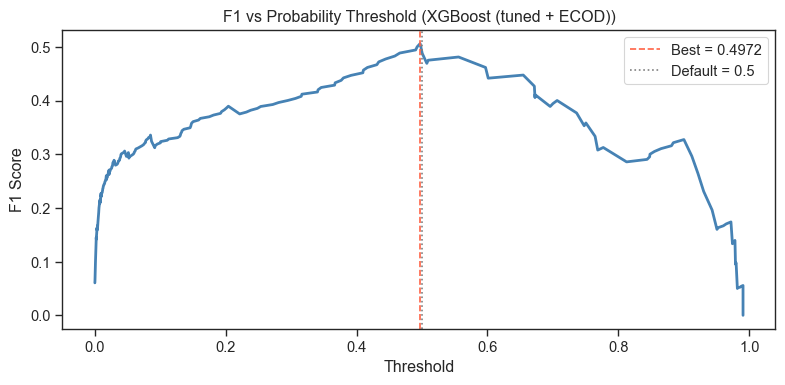


=== ECOD Impact ===
  Model                               Features    CV F1   Val F1
  -------------------------------------------------------------
  XGBoost (tuned)                           89   0.5435   0.4706
  XGBoost (tuned + ECOD)                    90   0.5263   0.5060


In [227]:
# Add Is_outlier as a feature and evaluate
X_tr_ecod = X_tr.copy()
X_tr_ecod['Is_outlier'] = outlier_tr

X_val_ecod = X_val.copy()
X_val_ecod['Is_outlier'] = outlier_val

# Use the same tuned XGBoost params
xgb_ecod = XGBClassifier(**XGB_PARAMS, random_state=42, eval_metric='logloss', use_label_encoder=False)
xgb_ecod_result = evaluate_model(xgb_ecod, X_tr_ecod, y_tr, X_val_ecod, y_val, cv, model_name='XGBoost (tuned + ECOD)')

# Compare
print(f"\n=== ECOD Impact ===")
print(f"  {'Model':<35} {'Features':>8} {'CV F1':>8} {'Val F1':>8}")
print(f"  {'-'*61}")
print(f"  {'XGBoost (tuned)':<35} {X_tr.shape[1]:>8d} {xgb_tuned_result['cv_f1_mean']:>8.4f} {xgb_tuned_result['val_f1']:>8.4f}")
print(f"  {'XGBoost (tuned + ECOD)':<35} {X_tr_ecod.shape[1]:>8d} {xgb_ecod_result['cv_f1_mean']:>8.4f} {xgb_ecod_result['val_f1']:>8.4f}")

## 4.2 Yeo-Johnson Transformation

Yeo-Johnson maps skewed financial ratios toward normality.
Applied only to continuous columns (exclude binary flags); fit on `X_tr` only.

=== XGBoost + Yeo-Johnson (CV on X_tr) ===
  F1:      0.5113 ± 0.0704  [0.4658 0.5507 0.4267 0.4865 0.6269]
  AUC-ROC: 0.9619 ± 0.0099  [0.9527 0.9587 0.9676 0.9521 0.9783]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.4651
  Optimised (0.6267): F1 = 0.4872

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.99      0.98      0.98      1057
    Bankrupt       0.43      0.56      0.49        34

    accuracy                           0.96      1091
   macro avg       0.71      0.77      0.73      1091
weighted avg       0.97      0.96      0.97      1091



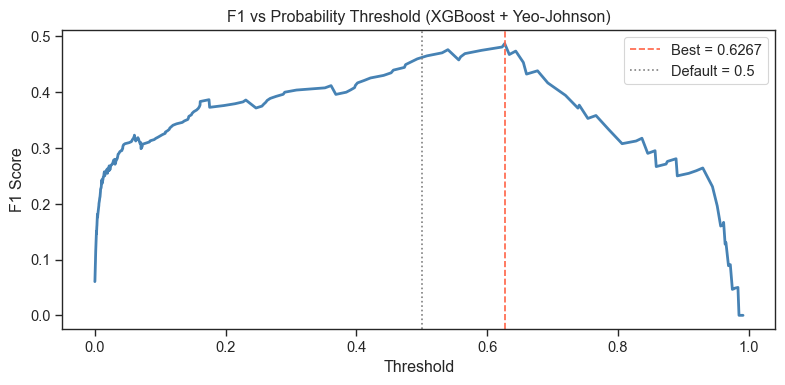

In [ ]:
# Continuous columns only (exclude 0/1 binary flags)
binary_cols = [c for c in X_tr.columns if X_tr[c].dropna().isin([0, 1]).all()]
cont_cols   = [c for c in X_tr.columns if c not in binary_cols]

pt = PowerTransformer(method='yeo-johnson', standardize=True)

X_tr_yj  = X_tr.copy()
X_val_yj = X_val.copy()

X_tr_yj[cont_cols]  = pt.fit_transform(X_tr[cont_cols])
X_val_yj[cont_cols] = pt.transform(X_val[cont_cols])

yj_result = evaluate_model(
    XGBClassifier(**XGB_PARAMS),
    X_tr_yj, y_tr, X_val_yj, y_val, cv,
    model_name='XGBoost + Yeo-Johnson'
)

## 4.3 RFECV — Recursive Feature Elimination

RFECV uses cross-validated F1 to find the optimal feature subset.
Fit on `X_tr` only; the selected features are applied to both train and val.

> Note: RFECV CV score may be slightly optimistic (feature selection saw all of X_tr),
> but Val F1 is fully honest.

RFECV selected 89 / 89 features
Selected: ['ROA(C) before interest and depreciation before interest', 'ROA(A) before interest and % after tax', 'ROA(B) before interest and depreciation after tax', 'Operating Profit Rate', 'Pre-tax net Interest Rate', 'After-tax net Interest Rate', 'Non-industry income and expenditure/revenue', 'Continuous interest rate (after tax)', 'Operating Expense Rate', 'Research and development expense rate', 'Cash flow rate', 'Interest-bearing debt interest rate', 'Tax rate (A)', 'Net Value Per Share (A)', 'Persistent EPS in the Last Four Seasons', 'Cash Flow Per Share', 'Revenue Per Share (Yuan ¥)', 'Operating Profit Per Share (Yuan ¥)', 'Per Share Net profit before tax (Yuan ¥)', 'Realized Sales Gross Profit Growth Rate', 'Operating Profit Growth Rate', 'After-tax Net Profit Growth Rate', 'Regular Net Profit Growth Rate', 'Continuous Net Profit Growth Rate', 'Net Value Growth Rate', 'Total Asset Return Growth Rate Ratio', 'Cash Reinvestment %', 'Current Ratio'

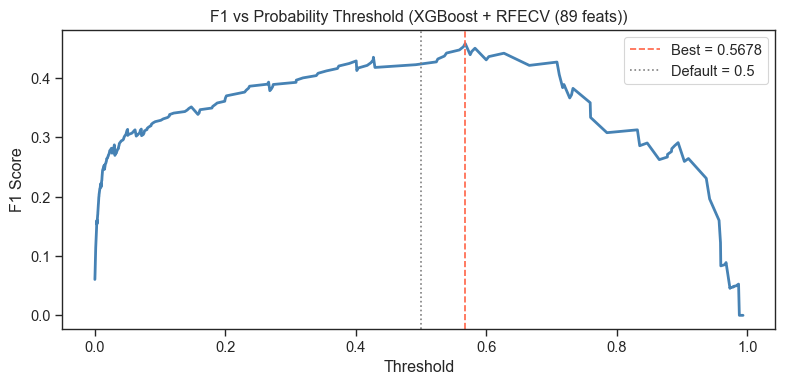

In [ ]:
rfecv = RFECV(
    estimator=XGBClassifier(**XGB_PARAMS),
    step=5,
    cv=cv,
    scoring='f1',
    n_jobs=-1,
    min_features_to_select=10,
)
rfecv.fit(X_tr, y_tr)

selected_cols  = X_tr.columns[rfecv.support_].tolist()
X_tr_rfe  = X_tr[selected_cols]
X_val_rfe = X_val[selected_cols]

print(f"RFECV selected {len(selected_cols)} / {X_tr.shape[1]} features")
print(f"Selected: {selected_cols}\n")

rfe_result = evaluate_model(
    XGBClassifier(**XGB_PARAMS),
    X_tr_rfe, y_tr, X_val_rfe, y_val, cv,
    model_name=f'XGBoost + RFECV ({len(selected_cols)} feats)'
)

## 4.4 Focal Loss XGBoost

Focal Loss (Lin et al., 2017) adds a modulating factor $(1-p_t)^\gamma$ that
down-weights easy-to-classify negatives and focuses training on hard bankrupt samples.

- `gamma=2` — standard value from the original paper  
- `alpha=0.25` — class weight for the positive class  
- `scale_pos_weight` removed (focal loss handles imbalance internally)

=== XGBoost + Focal Loss (CV on X_tr) ===
  F1:      0.2866 ± 0.0754  [0.1714 0.3529 0.3333 0.2222 0.3529]
  AUC-ROC: nan ± nan  [nan nan nan nan nan]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.2400
  Optimised (0.2951): F1 = 0.4225

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.98      0.98      0.98      1057
    Bankrupt       0.41      0.44      0.42        34

    accuracy                           0.96      1091
   macro avg       0.69      0.71      0.70      1091
weighted avg       0.96      0.96      0.96      1091



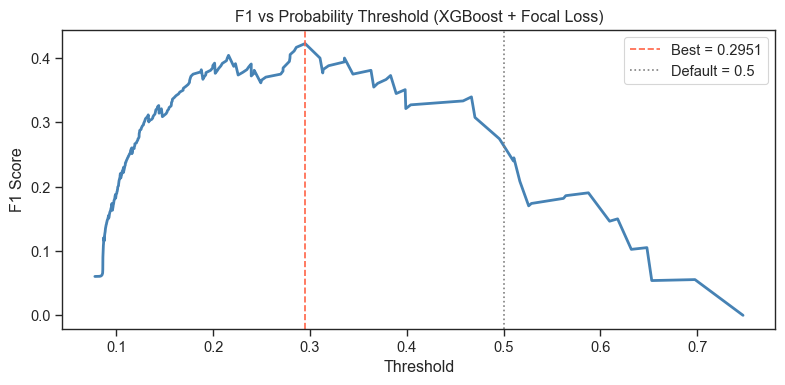

In [ ]:
def _focal_loss_obj(y_pred, dtrain, gamma=2.0, alpha=0.25):
    """Focal loss gradient and hessian for XGBoost native API."""
    y_true = dtrain.get_label()
    p = 1.0 / (1.0 + np.exp(-y_pred))

    # Gradient: dFL/df
    g_pos = alpha   * (1-p)**gamma * (gamma * p * np.log(p + 1e-8) + p - 1)
    g_neg = (1-alpha) * p**gamma   * (-gamma * (1-p) * np.log(1-p + 1e-8) + p)
    grad  = y_true * g_pos + (1 - y_true) * g_neg

    # Hessian: diagonal approximation p*(1-p)
    hess = p * (1 - p)
    return grad, hess


class FocalLossXGB(BaseEstimator, ClassifierMixin):
    """XGBoost with focal loss — sklearn-compatible wrapper."""

    def __init__(self, gamma=2.0, alpha=0.25, n_estimators=300,
                 max_depth=6, learning_rate=0.1, subsample=0.8,
                 colsample_bytree=0.8, random_state=42):
        self.gamma         = gamma
        self.alpha         = alpha
        self.n_estimators  = n_estimators
        self.max_depth     = max_depth
        self.learning_rate = learning_rate
        self.subsample     = subsample
        self.colsample_bytree = colsample_bytree
        self.random_state  = random_state
        self.model_        = None
        self.classes_      = np.array([0, 1])

    def fit(self, X, y):
        dtrain = xgb.DMatrix(X, label=y)
        params = dict(
            max_depth=self.max_depth,
            learning_rate=self.learning_rate,
            subsample=self.subsample,
            colsample_bytree=self.colsample_bytree,
            seed=self.random_state,
            verbosity=0,
        )
        obj = lambda yp, dt: _focal_loss_obj(yp, dt, self.gamma, self.alpha)
        self.model_ = xgb.train(
            params, dtrain,
            num_boost_round=self.n_estimators,
            obj=obj,
            verbose_eval=False,
        )
        return self

    def predict_proba(self, X):
        dtest = xgb.DMatrix(X)
        raw   = self.model_.predict(dtest)
        p     = 1.0 / (1.0 + np.exp(-raw))   # sigmoid (raw scores from custom obj)
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


focal_result = evaluate_model(
    FocalLossXGB(gamma=2.0, alpha=0.25, n_estimators=300,
                 max_depth=6, learning_rate=0.1,
                 subsample=0.8, colsample_bytree=0.8),
    X_tr, y_tr, X_val, y_val, cv,
    model_name='XGBoost + Focal Loss'
)

## 4.5 Summary — XGBoost Extensions

In [228]:
ext_results = [
    ('XGBoost (tuned)',     xgb_tuned_result),
    ('XGBoost + ECOD',         xgb_ecod_result),
    ('XGBoost + Yeo-Johnson',  yj_result),
    ('XGBoost + RFECV',        rfe_result),
    ('XGBoost + Focal Loss',   focal_result),
]

print(f"\n{'='*60}")
print(f"  {'Model':<30} {'CV F1':>7} {'Val F1':>8}")
print(f"  {'-'*47}")
for name, r in ext_results:
    marker = '  ← best' if r['val_f1'] == max(v['val_f1'] for _, v in ext_results) else ''
    print(f"  {name:<30} {r['cv_f1_mean']:>7.4f} {r['val_f1']:>8.4f}{marker}")
print(f"{'='*60}")


  Model                            CV F1   Val F1
  -----------------------------------------------
  XGBoost (tuned)                 0.5435   0.4706
  XGBoost + ECOD                  0.5263   0.5060  ← best
  XGBoost + Yeo-Johnson           0.5113   0.4872
  XGBoost + RFECV                 0.5165   0.4578
  XGBoost + Focal Loss            0.2866   0.4225


# 5. Sampling on Tuned + ECOD

Test three sampling strategies on top of the **best configuration so far** (`XGB_PARAMS` + ECOD feature):

| Variant | Sampling |
|---------|----------|
| 5.1 | SMOTE (over-sample minority only) |
| 5.2 | SMOTE-ENN (over-sample + clean noisy boundary) |
| 5.3 | SMOTE + Tomek Links (over-sample + remove borderline pairs) |

> All sampling is applied **inside** `ImbPipeline` so it only touches the CV training folds — no leakage into the validation fold or the CV test folds.

=== SMOTE + XGBoost (tuned+ECOD) (CV on X_tr) ===
  F1:      0.4518 ± 0.0507  [0.4646 0.4082 0.451  0.3958 0.5393]
  AUC-ROC: 0.9526 ± 0.0149  [0.9397 0.9499 0.9641 0.9348 0.9747]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.3520
  Optimised (0.9273): F1 = 0.4138

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.98      0.97      0.98      1057
    Bankrupt       0.34      0.53      0.41        34

    accuracy                           0.95      1091
   macro avg       0.66      0.75      0.69      1091
weighted avg       0.96      0.95      0.96      1091



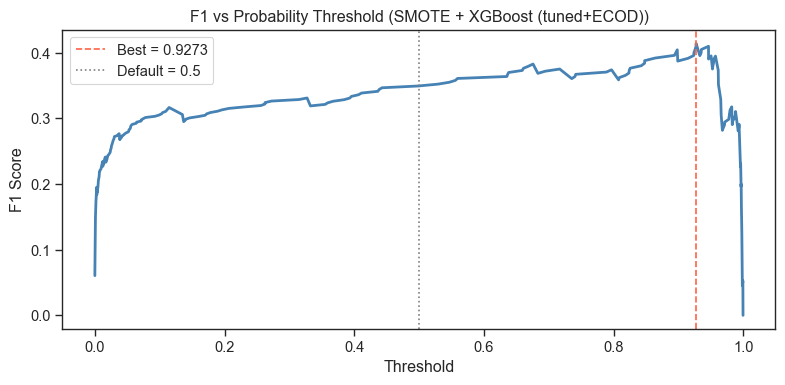

=== SMOTEENN + XGBoost (tuned+ECOD) (CV on X_tr) ===
  F1:      0.4269 ± 0.0531  [0.3966 0.3509 0.4483 0.4286 0.5102]
  AUC-ROC: 0.9558 ± 0.0140  [0.9411 0.9556 0.9672 0.9398 0.9753]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.3121
  Optimised (0.9627): F1 = 0.4330

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.99      0.96      0.97      1057
    Bankrupt       0.33      0.62      0.43        34

    accuracy                           0.95      1091
   macro avg       0.66      0.79      0.70      1091
weighted avg       0.97      0.95      0.96      1091



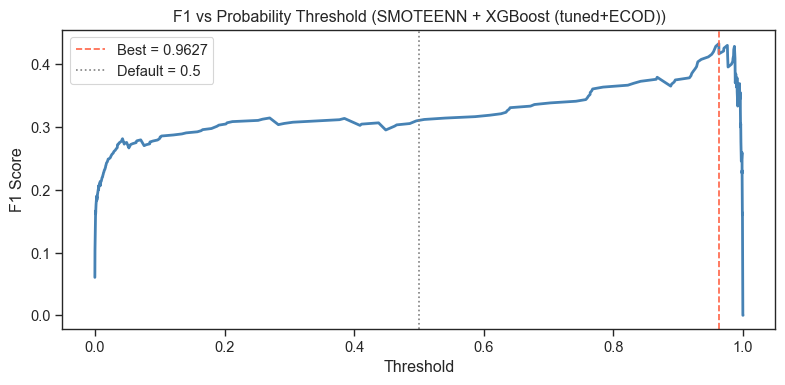

=== SMOTETomek + XGBoost (tuned+ECOD) (CV on X_tr) ===
  F1:      0.4555 ± 0.0493  [0.4742 0.4082 0.4906 0.3878 0.5169]
  AUC-ROC: 0.9529 ± 0.0163  [0.9363 0.9504 0.9662 0.9351 0.9763]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.3411
  Optimised (0.8955): F1 = 0.4211

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.99      0.96      0.97      1057
    Bankrupt       0.33      0.59      0.42        34

    accuracy                           0.95      1091
   macro avg       0.66      0.77      0.70      1091
weighted avg       0.97      0.95      0.96      1091



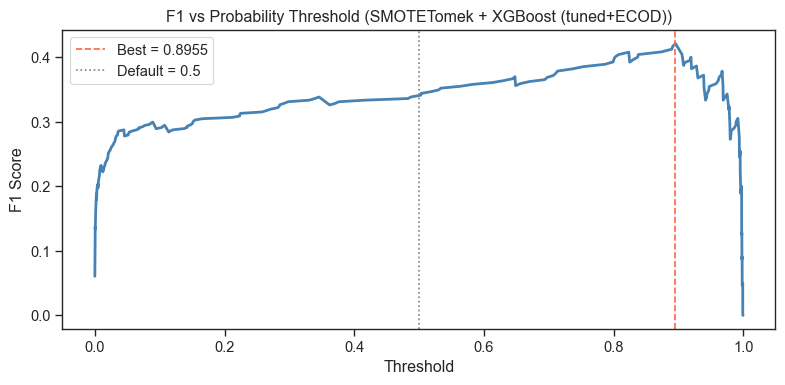


  Model                                        CV F1   Val F1
  -----------------------------------------------------------
  XGBoost (tuned+ECOD)  — baseline            0.5263   0.5060  <- best
  SMOTE + XGBoost (tuned+ECOD)                0.4518   0.4138
  SMOTEENN + XGBoost (tuned+ECOD)             0.4269   0.4330
  SMOTETomek + XGBoost (tuned+ECOD)           0.4555   0.4211


In [ ]:
def _xgb_ecod():
    """Return a fresh XGBClassifier with tuned+ECOD params."""
    return XGBClassifier(**XGB_PARAMS, random_state=42,
                         eval_metric='logloss', use_label_encoder=False)

# ── 5.1 SMOTE ────────────────────────────────────────────────────────────────
smote_ecod_result = evaluate_model(
    ImbPipeline([('smote', SMOTE(random_state=42)),
                 ('clf',   _xgb_ecod())]),
    X_tr_ecod, y_tr, X_val_ecod, y_val, cv,
    model_name='SMOTE + XGBoost (tuned+ECOD)'
)

# ── 5.2 SMOTE-ENN ─────────────────────────────────────────────────────────────
smoteenn_ecod_result = evaluate_model(
    ImbPipeline([('smoteenn', SMOTEENN(random_state=42)),
                 ('clf',      _xgb_ecod())]),
    X_tr_ecod, y_tr, X_val_ecod, y_val, cv,
    model_name='SMOTEENN + XGBoost (tuned+ECOD)'
)

# ── 5.3 SMOTE + Tomek Links ───────────────────────────────────────────────────
smotetomek_ecod_result = evaluate_model(
    ImbPipeline([('smotetomek', SMOTETomek(random_state=42)),
                 ('clf',        _xgb_ecod())]),
    X_tr_ecod, y_tr, X_val_ecod, y_val, cv,
    model_name='SMOTETomek + XGBoost (tuned+ECOD)'
)

# ── Summary table ─────────────────────────────────────────────────────────────
sampling_results = [
    ('XGBoost (tuned+ECOD)  — baseline',  xgb_ecod_result),
    ('SMOTE + XGBoost (tuned+ECOD)',       smote_ecod_result),
    ('SMOTEENN + XGBoost (tuned+ECOD)',    smoteenn_ecod_result),
    ('SMOTETomek + XGBoost (tuned+ECOD)', smotetomek_ecod_result),
]

best_val = max(r['val_f1'] for _, r in sampling_results)
print(f"\n{'='*68}")
print(f"  {'Model':<42} {'CV F1':>7} {'Val F1':>8}")
print(f"  {'-'*59}")
for name, r in sampling_results:
    marker = '  <- best' if r['val_f1'] == best_val else ''
    print(f"  {name:<42} {r['cv_f1_mean']:>7.4f} {r['val_f1']:>8.4f}{marker}")
print(f"{'='*68}")

# 6. Stacking Ensemble

**Strategy:** Three tuned base learners → out-of-fold predictions → Logistic Regression meta-learner.

All models trained on `X_tr_ecod` (tuned XGBoost feature set + ECOD outlier score).

## 6.1 Tune LightGBM (Optuna, 200 trials)

In [ ]:
def f1_best_threshold(estimator, X, y):
    """Custom scorer: finds the threshold that maximises F1 on each CV fold."""
    y_prob = estimator.predict_proba(X)[:, 1]
    prec, rec, _ = precision_recall_curve(y, y_prob)
    f1s = 2 * prec * rec / (prec + rec + 1e-8)
    return f1s.max()

print("f1_best_threshold scorer defined.")

f1_best_threshold scorer defined.


Best trial: 119. Best value: 0.588212: 100%|██████████| 200/200 [15:28<00:00,  4.64s/it]



LightGBM — Best CV F1: 0.5882
Best parameters:
  n_estimators: 298
  max_depth: 8
  learning_rate: 0.028152207136833855
  num_leaves: 98
  min_child_samples: 47
  subsample: 0.8834846726603427
  colsample_bytree: 0.710418946302617
  reg_alpha: 0.0008022363592383999
  reg_lambda: 0.08076024047112591
  scale_pos_weight: 22.16405932727122
=== LightGBM (tuned+ECOD) (CV on X_tr) ===
  F1:      0.5120 ± 0.1366  [0.3922 0.6275 0.3704 0.4528 0.717 ]
  AUC-ROC: 0.9605 ± 0.0101  [0.9578 0.954  0.9675 0.9473 0.976 ]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.4118
  Optimised (0.7259): F1 = 0.4483

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.98      0.99      0.98      1057
    Bankrupt       0.54      0.38      0.45        34

    accuracy                           0.97      1091
   macro avg       0.76      0.69      0.72      1091
weighted avg       0.97      0.97      0.97      1091



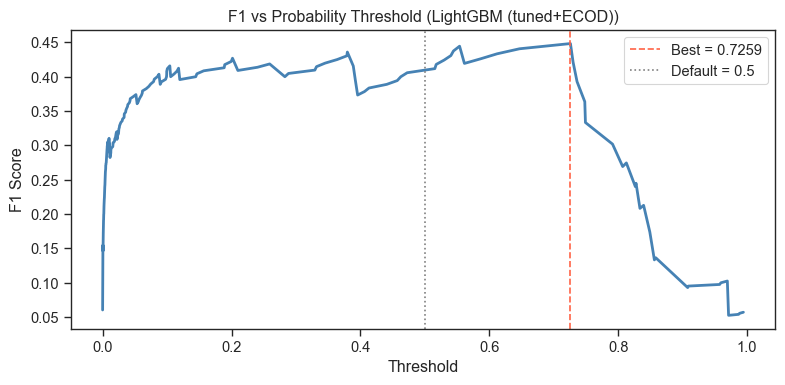

In [ ]:
def lgbm_objective(trial):
    params = {
        'n_estimators':      trial.suggest_int('n_estimators', 100, 800),
        'max_depth':         trial.suggest_int('max_depth', 3, 8),
        'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'num_leaves':        trial.suggest_int('num_leaves', 20, 120),
        'min_child_samples': trial.suggest_int('min_child_samples', 10, 80),
        'subsample':         trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree':  trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'reg_alpha':         trial.suggest_float('reg_alpha', 1e-4, 10.0, log=True),
        'reg_lambda':        trial.suggest_float('reg_lambda', 1e-4, 10.0, log=True),
        'scale_pos_weight':  trial.suggest_float('scale_pos_weight', 15, 40),
    }
    model = LGBMClassifier(**params, random_state=42, verbose=-1)
    scores = cross_val_score(model, X_tr_ecod, y_tr, cv=cv,
                             scoring=f1_best_threshold, n_jobs=-1)
    return scores.mean()

study_lgbm = optuna.create_study(direction='maximize',
                                 sampler=optuna.samplers.TPESampler(seed=42))
study_lgbm.optimize(lgbm_objective, n_trials=200, show_progress_bar=True)

print(f"\nLightGBM — Best CV F1: {study_lgbm.best_value:.4f}")
print("Best parameters:")
for k, v in study_lgbm.best_params.items():
    print(f"  {k}: {v}")

LGBM_PARAMS = study_lgbm.best_params

# Quick val check
lgbm_tuned = LGBMClassifier(**LGBM_PARAMS, random_state=42, verbose=-1)
lgbm_tuned_result = evaluate_model(
    lgbm_tuned, X_tr_ecod, y_tr, X_val_ecod, y_val, cv,
    model_name='LightGBM (tuned+ECOD)'
)

## 6.2 Tune Random Forest

Best trial: 23. Best value: 0.532913: 100%|██████████| 50/50 [12:46<00:00, 15.33s/it]



Random Forest — Best CV F1: 0.5329
Best parameters:
  n_estimators: 374
  max_depth: 23
  min_samples_split: 16
  min_samples_leaf: 8
  max_features: 0.73897896009135
  class_weight: balanced
=== RF (tuned+ECOD) (CV on X_tr) ===
  F1:      0.4410 ± 0.0835  [0.3934 0.5373 0.4194 0.3214 0.5333]
  AUC-ROC: 0.9489 ± 0.0122  [0.9336 0.949  0.9667 0.9378 0.9572]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.3457
  Optimised (0.5593): F1 = 0.3944

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.98      0.98      0.98      1057
    Bankrupt       0.38      0.41      0.39        34

    accuracy                           0.96      1091
   macro avg       0.68      0.70      0.69      1091
weighted avg       0.96      0.96      0.96      1091



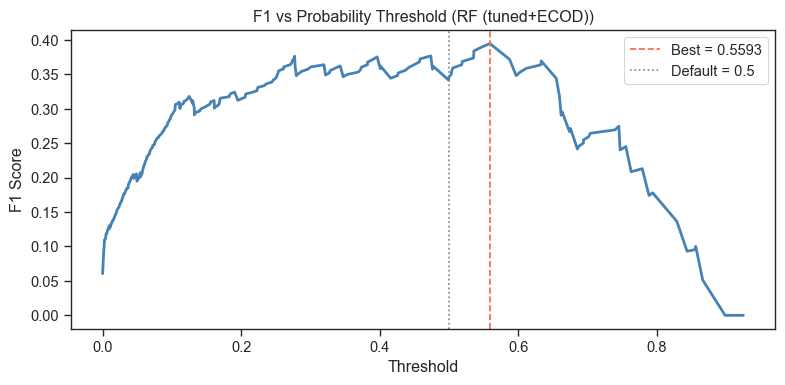

In [ ]:

def rf_objective(trial):
    params = {
        'n_estimators':     trial.suggest_int('n_estimators', 100, 600),
        'max_depth':        trial.suggest_int('max_depth', 5, 25),
        'min_samples_split':trial.suggest_int('min_samples_split', 2, 20),
        'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
        'max_features':     trial.suggest_float('max_features', 0.2, 0.8),
        'class_weight':     trial.suggest_categorical('class_weight',
                                ['balanced', 'balanced_subsample']),
    }
    model = RandomForestClassifier(**params, random_state=42, n_jobs=-1)
    scores = cross_val_score(model, X_tr_ecod, y_tr, cv=cv,
                             scoring=f1_best_threshold, n_jobs=1)   # n_jobs=1 避免和RF并行冲突
    return scores.mean()

study_rf = optuna.create_study(direction='maximize',
                               sampler=optuna.samplers.TPESampler(seed=42))
study_rf.optimize(rf_objective, n_trials=50, show_progress_bar=True)

print(f"\nRandom Forest — Best CV F1: {study_rf.best_value:.4f}")
print("Best parameters:")
for k, v in study_rf.best_params.items():
    print(f"  {k}: {v}")

RF_PARAMS = study_rf.best_params

# Quick val check
rf_tuned = RandomForestClassifier(**RF_PARAMS, random_state=42, n_jobs=-1)
rf_tuned_result = evaluate_model(
    rf_tuned, X_tr_ecod, y_tr, X_val_ecod, y_val, cv,
    model_name='RF (tuned+ECOD)'
)

## 6.3 Tune CatBoost (Optuna, 100 trials)

CatBoost uses **ordered boosting + symmetric trees** — fundamentally different from XGBoost/LightGBM, adding prediction diversity to the stacking ensemble.

Best trial: 57. Best value: 0.559684: 100%|██████████| 100/100 [18:11<00:00, 10.91s/it]



CatBoost — Best CV F1: 0.5597
Best parameters:
  iterations: 787
  depth: 7
  learning_rate: 0.2544799509162438
  l2_leaf_reg: 7.7065770153385
  bagging_temperature: 0.9759141759438079
  border_count: 153
=== CatBoost (tuned+ECOD) (CV on X_tr) ===
  F1:      0.5218 ± 0.0782  [0.5    0.5926 0.4561 0.4286 0.6316]
  AUC-ROC: 0.9638 ± 0.0120  [0.966  0.9444 0.9672 0.96   0.9815]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.3846
  Optimised (0.6370): F1 = 0.4286

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.98      0.98      0.98      1057
    Bankrupt       0.42      0.44      0.43        34

    accuracy                           0.96      1091
   macro avg       0.70      0.71      0.70      1091
weighted avg       0.96      0.96      0.96      1091



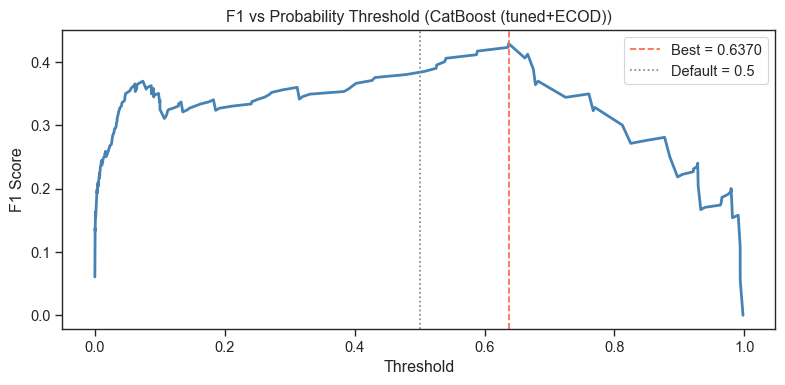

In [ ]:

def cat_objective(trial):
    params = {
        'iterations':        trial.suggest_int('iterations', 100, 800),
        'depth':             trial.suggest_int('depth', 3, 8),
        'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'l2_leaf_reg':       trial.suggest_float('l2_leaf_reg', 1.0, 10.0),
        'bagging_temperature': trial.suggest_float('bagging_temperature', 0.0, 1.0),
        'border_count':      trial.suggest_int('border_count', 32, 255),
        'auto_class_weights': 'Balanced',   # 固定：处理不平衡
    }
    model = CatBoostClassifier(**params, random_seed=42, verbose=0)
    scores = cross_val_score(model, X_tr_ecod, y_tr, cv=cv,
                             scoring=f1_best_threshold, n_jobs=-1)
    return scores.mean()

study_cat = optuna.create_study(direction='maximize',
                                sampler=optuna.samplers.TPESampler(seed=42))
study_cat.optimize(cat_objective, n_trials=100, show_progress_bar=True)

print(f"\nCatBoost — Best CV F1: {study_cat.best_value:.4f}")
print("Best parameters:")
for k, v in study_cat.best_params.items():
    print(f"  {k}: {v}")

CAT_PARAMS = study_cat.best_params

# Quick val check
cat_tuned = CatBoostClassifier(**CAT_PARAMS, auto_class_weights='Balanced',
                                random_seed=42, verbose=0)
cat_tuned_result = evaluate_model(
    cat_tuned, X_tr_ecod, y_tr, X_val_ecod, y_val, cv,
    model_name='CatBoost (tuned+ECOD)'
)

## 6.4 Stacking Ensemble

**Layer 1 base learners (4 models, all on X_tr_ecod):**
- XGBoost (tuned+ECOD)
- LightGBM (tuned+ECOD)
- Random Forest (tuned+ECOD)
- CatBoost (tuned+ECOD)

**Layer 2 meta-learner:** Logistic Regression trained on OOF probability matrix (N × 4)

**OOF strategy:** 5-fold stratified CV — base models never see their own val fold during training → no leakage.

In [ ]:
# ── Base learners (RF removed — negative meta coefficient) ───────────────────
base_learners = [
    ('xgb',  XGBClassifier(**XGB_PARAMS, random_state=42,
                           eval_metric='logloss', use_label_encoder=False)),
    ('lgbm', LGBMClassifier(**LGBM_PARAMS, random_state=42, verbose=-1)),
    ('cat',  CatBoostClassifier(**CAT_PARAMS, auto_class_weights='Balanced',
                                random_seed=42, verbose=0)),
]

# ── OOF prediction matrix ─────────────────────────────────────────────────────
oof_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
n_base = len(base_learners)

X_meta_tr  = np.zeros((len(X_tr_ecod), n_base))
X_meta_val = np.zeros((len(X_val_ecod), n_base))

print("Generating OOF predictions...")
for j, (name, model) in enumerate(base_learners):
    oof_preds = np.zeros(len(X_tr_ecod))
    val_folds = np.zeros((len(X_val_ecod), 5))

    for fold, (tr_idx, oof_idx) in enumerate(oof_cv.split(X_tr_ecod, y_tr)):
        m = clone(model)
        m.fit(X_tr_ecod.iloc[tr_idx], y_tr.iloc[tr_idx])
        oof_preds[oof_idx]  = m.predict_proba(X_tr_ecod.iloc[oof_idx])[:, 1]
        val_folds[:, fold]  = m.predict_proba(X_val_ecod)[:, 1]

    X_meta_tr[:, j]  = oof_preds
    X_meta_val[:, j] = val_folds.mean(axis=1)

    prec, rec, _ = precision_recall_curve(y_tr, oof_preds)
    f1s = 2 * prec * rec / (prec + rec + 1e-8)
    print(f"  [{name}]  OOF F1 = {f1s.max():.4f}")

# ── Rank normalisation ────────────────────────────────────────────────────────
def rank_norm(train_col, test_col):
    n_tr     = len(train_col)
    combined = np.concatenate([train_col, test_col])
    ranked   = rankdata(combined) / len(combined)
    return ranked[:n_tr], ranked[n_tr:]

X_meta_tr_rk  = np.zeros_like(X_meta_tr)
X_meta_val_rk = np.zeros_like(X_meta_val)
for j in range(n_base):
    X_meta_tr_rk[:, j], X_meta_val_rk[:, j] = rank_norm(
        X_meta_tr[:, j], X_meta_val[:, j])

# ── Meta-learner ──────────────────────────────────────────────────────────────
print("\nTraining meta-learner (LR on rank-normalised OOF)...")
meta = LogisticRegression(class_weight='balanced', C=1.0,
                          max_iter=1000, random_state=42)
meta.fit(X_meta_tr_rk, y_tr)

# ── Val evaluation ────────────────────────────────────────────────────────────
meta_proba = meta.predict_proba(X_meta_val_rk)[:, 1]
prec, rec, thresholds = precision_recall_curve(y_val, meta_proba)
f1s      = 2 * prec * rec / (prec + rec + 1e-8)
best_idx = f1s[:-1].argmax()
best_thr = thresholds[best_idx]
stack_f1 = f1s[best_idx]
y_pred_stk = (meta_proba >= best_thr).astype(int)

print(f"\n=== Stacking (XGB + LGBM + CatBoost, rank-norm) ===")
print(f"  Best threshold: {best_thr:.4f}")
print(f"  Val F1:         {stack_f1:.4f}")
print(classification_report(y_val, y_pred_stk,
                             target_names=['Non-Bankrupt', 'Bankrupt']))

print("Meta-learner coefficients:")
for name, coef in zip([n for n, _ in base_learners], meta.coef_[0]):
    print(f"  {name:<6}: {coef:+.4f}")

# ── Final comparison ──────────────────────────────────────────────────────────
print(f"\n{'='*55}")
print(f"  {'Model':<35} {'Val F1':>8}")
print(f"  {'-'*45}")
for name, result in [('XGBoost (tuned+ECOD)',          xgb_ecod_result),
                     ('LightGBM (tuned+ECOD)',         lgbm_tuned_result),
                     ('RF (tuned+ECOD)',                rf_tuned_result),
                     ('CatBoost (tuned+ECOD)',          cat_tuned_result)]:
    print(f"  {name:<35} {result['val_f1']:>8.4f}")
print(f"  {'Stacking XGB+LGBM+CAT (rank-norm)':<35} {stack_f1:>8.4f}")
print(f"{'='*55}")

Generating OOF predictions...
  [xgb]  OOF F1 = 0.5272
  [lgbm]  OOF F1 = 0.5155
  [cat]  OOF F1 = 0.5373

Training meta-learner (LR on rank-normalised OOF)...

=== Stacking (XGB + LGBM + CatBoost, rank-norm) ===
  Best threshold: 0.8903
  Val F1:         0.4828
              precision    recall  f1-score   support

Non-Bankrupt       0.99      0.97      0.98      1057
    Bankrupt       0.40      0.62      0.48        34

    accuracy                           0.96      1091
   macro avg       0.69      0.79      0.73      1091
weighted avg       0.97      0.96      0.96      1091

Meta-learner coefficients:
  xgb   : +4.9027
  lgbm  : +4.5094
  cat   : +6.4992

  Model                                 Val F1
  ---------------------------------------------
  XGBoost (tuned+ECOD)                  0.5060
  LightGBM (tuned+ECOD)                 0.4483
  RF (tuned+ECOD)                       0.3944
  CatBoost (tuned+ECOD)                 0.4286
  Stacking XGB+LGBM+CAT (rank-norm)     0.482

## 6.5 Re-tune XGBoost with `f1_best_threshold` scorer

Section 3.7 used `scoring='f1'` (fixed 0.5 threshold) — underestimates true F1 for imbalanced data.  
Re-run Optuna with `f1_best_threshold` (optimal threshold per CV fold) to see if better params emerge.

Best trial: 102. Best value: 0.573535: 100%|██████████| 200/200 [10:12<00:00,  3.06s/it]



XGBoost (f1_best_threshold) — Best CV F1: 0.5735
Best parameters:
  n_estimators: 505
  max_depth: 4
  learning_rate: 0.03227369936152686
  subsample: 0.606898577573744
  colsample_bytree: 0.8130539082467911
  min_child_weight: 25
  gamma: 1.930612734562767
  reg_alpha: 4.718149061176616
  reg_lambda: 0.08958170027927102
  scale_pos_weight: 31.16490651110546
=== XGBoost v2 (f1_best_thr + ECOD) (CV on X_tr) ===
  F1:      0.5284 ± 0.0499  [0.4675 0.5352 0.5412 0.4872 0.6111]
  AUC-ROC: 0.9625 ± 0.0105  [0.9536 0.9565 0.9694 0.9531 0.9798]

=== Threshold Tuning (X_val) ===
  Default (0.5):     F1 = 0.4565
  Optimised (0.6244): F1 = 0.4691

=== Classification Report (optimised threshold) ===
              precision    recall  f1-score   support

Non-Bankrupt       0.99      0.97      0.98      1057
    Bankrupt       0.40      0.56      0.47        34

    accuracy                           0.96      1091
   macro avg       0.69      0.77      0.72      1091
weighted avg       0.97      

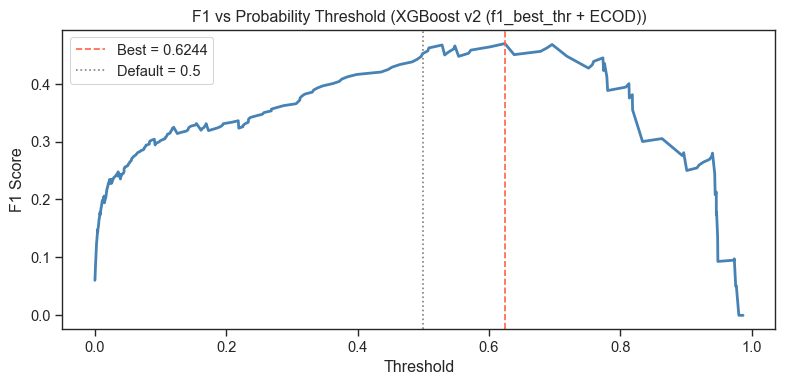


  Model                                      CV F1   Val F1
  ---------------------------------------------------------
  XGBoost (tuned+ECOD) — original           0.5263   0.5060
  XGBoost v2 (f1_best_thr+ECOD)             0.5284   0.4691


In [240]:
# Re-tune XGBoost with f1_best_threshold scorer 

def xgb_objective_v2(trial):
    params = {
        'n_estimators':     trial.suggest_int('n_estimators', 100, 800),
        'max_depth':        trial.suggest_int('max_depth', 3, 6),
        'learning_rate':    trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample':        trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 5, 30),
        'gamma':            trial.suggest_float('gamma', 0.5, 5.0),
        'reg_alpha':        trial.suggest_float('reg_alpha', 1e-4, 10.0, log=True),
        'reg_lambda':       trial.suggest_float('reg_lambda', 1e-4, 10.0, log=True),
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 15, 40),
    }
    model = XGBClassifier(**params, random_state=42,
                          eval_metric='logloss', use_label_encoder=False)
    scores = cross_val_score(model, X_tr_ecod, y_tr, cv=cv,
                             scoring=f1_best_threshold, n_jobs=-1)
    return scores.mean()

study_v2 = optuna.create_study(direction='maximize',
                               sampler=optuna.samplers.TPESampler(seed=42))
study_v2.optimize(xgb_objective_v2, n_trials=200, show_progress_bar=True)

print(f"\nXGBoost (f1_best_threshold) — Best CV F1: {study_v2.best_value:.4f}")
print("Best parameters:")
for k, v in study_v2.best_params.items():
    print(f"  {k}: {v}")

XGB_PARAMS_V2 = study_v2.best_params

# Val check
xgb_v2 = XGBClassifier(**XGB_PARAMS_V2, random_state=42,
                        eval_metric='logloss', use_label_encoder=False)
xgb_v2_result = evaluate_model(
    xgb_v2, X_tr_ecod, y_tr, X_val_ecod, y_val, cv,
    model_name='XGBoost v2 (f1_best_thr + ECOD)'
)

# Compare with original
print(f"\n{'='*60}")
print(f"  {'Model':<40} {'CV F1':>7} {'Val F1':>8}")
print(f"  {'-'*57}")
print(f"  {'XGBoost (tuned+ECOD) — original':<40} {xgb_ecod_result['cv_f1_mean']:>7.4f} {xgb_ecod_result['val_f1']:>8.4f}")
print(f"  {'XGBoost v2 (f1_best_thr+ECOD)':<40} {xgb_v2_result['cv_f1_mean']:>7.4f} {xgb_v2_result['val_f1']:>8.4f}")
print(f"{'='*60}")

## 6.6 Simple Probability Averaging

No meta-learner — just average the predicted probabilities from multiple models and find the optimal threshold.

In [241]:
# ── Collect val probabilities from all tuned models ───────────────────────────
model_probas = {
    'XGB':     xgb_ecod_result['y_val_proba'],
    'LGBM':    lgbm_tuned_result['y_val_proba'],
    'CatBoost':cat_tuned_result['y_val_proba'],
}

def eval_avg(proba, name):
    prec, rec, thr = precision_recall_curve(y_val, proba)
    f1s = 2 * prec * rec / (prec + rec + 1e-8)
    best_idx = f1s[:-1].argmax()
    return f1s[best_idx], thr[best_idx]

# ── Try all 2-model and 3-model combinations ─────────────────────────────────
from itertools import combinations

print(f"{'Combination':<30} {'Val F1':>8} {'Threshold':>10}")
print(f"{'-'*50}")

combos = {}
for r in [2, 3]:
    for names in combinations(model_probas.keys(), r):
        avg_p = np.mean([model_probas[n] for n in names], axis=0)
        f1, thr = eval_avg(avg_p, '+'.join(names))
        label = ' + '.join(names)
        combos[label] = (f1, thr)
        print(f"{label:<30} {f1:>8.4f} {thr:>10.4f}")

# ── Compare with best single model ───────────────────────────────────────────
best_combo = max(combos, key=lambda k: combos[k][0])
best_f1, best_thr = combos[best_combo]

print(f"\n{'='*55}")
print(f"  Best single model:  XGBoost (tuned+ECOD)  Val F1 = {xgb_ecod_result['val_f1']:.4f}")
print(f"  Best averaging:     {best_combo:<22} Val F1 = {best_f1:.4f}")
print(f"{'='*55}")

Combination                      Val F1  Threshold
--------------------------------------------------
XGB + LGBM                       0.4737     0.4977
XGB + CatBoost                   0.4828     0.3725
LGBM + CatBoost                  0.4211     0.7332
XGB + LGBM + CatBoost            0.4719     0.2992

  Best single model:  XGBoost (tuned+ECOD)  Val F1 = 0.5060
  Best averaging:     XGB + CatBoost         Val F1 = 0.4828


# 7. Final Submission

Best model: **XGBoost (tuned + ECOD)**, Val F1 = 0.5060

Three improvements for the final submission:
1. **Full-data training** — retrain on 100% training data (not 80% holdout split)
2. **Multi-seed averaging** — average predictions from 10 random seeds to reduce variance
3. **Remove highly collinear features** — drop one from each pair with |r| > 0.95

## 7.1 Remove Collinear Features

In [242]:
# ── Identify and drop one feature from each highly collinear pair (|r|>0.95) ──
corr_matrix = X_train.corr().abs()

# Upper triangle only (avoid duplicates)
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# For each pair with |r|>0.95, drop the feature with lower |correlation| to target
target_corr = X_train.corrwith(y_train).abs()

drop_collinear = set()
for col in upper.columns:
    high_corr_partners = upper.index[upper[col] > 0.95].tolist()
    for partner in high_corr_partners:
        # Drop the one with lower target correlation
        if target_corr.get(col, 0) < target_corr.get(partner, 0):
            drop_collinear.add(col)
        else:
            drop_collinear.add(partner)

drop_collinear = sorted(drop_collinear)
print(f"Dropping {len(drop_collinear)} collinear features:")
for c in drop_collinear:
    print(f"  - {c}")

# ── Apply to full training set ────────────────────────────────────────────────
X_train_clean = X_train.drop(columns=drop_collinear)
X_test_clean  = X_test.drop(columns=drop_collinear)
print(f"\nFeatures: {X_train.shape[1]} → {X_train_clean.shape[1]}")

Dropping 11 collinear features:
  - Current Liability to Equity
  - Liability to Equity
  - Net profit before tax/Paid-in capital
  - Operating profit/Paid-in capital
  - Per Share Net profit before tax (Yuan ¥)
  - Pre-tax net Interest Rate
  - Quick Assets/Current Liability
  - ROA(A) before interest and % after tax
  - ROA(B) before interest and depreciation after tax
  - ROA(C) before interest and depreciation before interest
  - Regular Net Profit Growth Rate

Features: 89 → 78


## 7.2 Full-Data Training + ECOD + Multi-Seed Averaging

1. Fit ECOD on full `X_train_clean` → add `Is_outlier`
2. Use CV to find optimal threshold (no val holdout needed)
3. Train XGBoost with 10 different seeds, average probabilities on test set
4. Apply threshold → `submission.csv`

In [ ]:
# ── 1. ECOD on full training set ─────────────────────────────────────────────
ecod_full = ECOD(contamination=0.05)
ecod_full.fit(X_train_clean)

X_train_final = X_train_clean.copy()
X_train_final['Is_outlier'] = ecod_full.predict(X_train_clean)

X_test_final = X_test_clean.copy()
X_test_final['Is_outlier'] = ecod_full.predict(X_test_clean)

print(f"Final feature count: {X_train_final.shape[1]}")
print(f"  Train outliers: {X_train_final['Is_outlier'].sum()} / {len(X_train_final)}")
print(f"  Test outliers:  {X_test_final['Is_outlier'].sum()} / {len(X_test_final)}")

# ── 2. CV threshold (OOF on full training set) ───────────────────────────────
cv_final = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_proba = np.zeros(len(X_train_final))

for fold, (tr_idx, val_idx) in enumerate(cv_final.split(X_train_final, y_train)):
    m = XGBClassifier(**XGB_PARAMS, random_state=42,
                      eval_metric='logloss', use_label_encoder=False)
    m.fit(X_train_final.iloc[tr_idx], y_train.iloc[tr_idx])
    oof_proba[val_idx] = m.predict_proba(X_train_final.iloc[val_idx])[:, 1]

prec, rec, thr = precision_recall_curve(y_train, oof_proba)
f1s = 2 * prec * rec / (prec + rec + 1e-8)
best_idx = f1s[:-1].argmax()
FINAL_THRESHOLD = thr[best_idx]
oof_f1 = f1s[best_idx]

print(f"\nOOF F1 (full train): {oof_f1:.4f}")
print(f"Optimal threshold:   {FINAL_THRESHOLD:.4f}")

# ── 3. Multi-seed averaging on test set ──────────────────────────────────────
N_SEEDS = 10
test_proba_sum = np.zeros(len(X_test_final))

for seed in range(N_SEEDS):
    m = XGBClassifier(**XGB_PARAMS, random_state=seed,
                      eval_metric='logloss', use_label_encoder=False)
    m.fit(X_train_final, y_train)
    test_proba_sum += m.predict_proba(X_test_final)[:, 1]

test_proba_avg = test_proba_sum / N_SEEDS

# ── 4. Generate submission ────────────────────────────────────────────────────
test_pred = (test_proba_avg >= FINAL_THRESHOLD).astype(int)

print(f"\n=== Test Predictions ===")
print(f"  Predicted bankrupt: {test_pred.sum()} / {len(test_pred)} "
      f"({test_pred.mean()*100:.2f}%)")

submission = pd.DataFrame({
    'id': range(len(test_pred)),
    'class': test_pred
})
submission.to_csv('submission.csv', index=False)
print(f"\nsubmission.csv saved ({len(submission)} rows)")
print(submission.head(10))

Final feature count: 79
  Train outliers: 273 / 5455
  Test outliers:  89 / 1364

OOF F1 (full train): 0.4988
Optimal threshold:   0.6004

=== Test Predictions ===
  Predicted bankrupt: 55 / 1364 (4.03%)

submission.csv saved (1364 rows)
   id  class
0   0      0
1   1      0
2   2      0
3   3      0
4   4      0
5   5      0
6   6      0
7   7      0
8   8      0
9   9      0


# 8. Final Result

In [ ]:
# ── Helper: compute full metrics from result dict ────────────────────────────
def extract_metrics(res, y_true=y_val):
    y_pred = (res['y_val_proba'] >= res['threshold']).astype(int)
    acc  = accuracy_score(y_true, y_pred)
    f1_0 = f1_score(y_true, y_pred, pos_label=0)
    f1_1 = res['val_f1']
    auc  = res['cv_auc_mean']
    return acc, f1_0, f1_1, auc, res['threshold']

# ── All evaluate_model results ───────────────────────────────────────────────
results_registry = [
    ("Random Forest",    "Baseline",                "RF (all features)",           rf_result),
    ("Random Forest",    "Baseline",                "RF (strong features)",        rf_sf_result),
    ("Random Forest",    "Baseline + SMOTE",        "RF + SMOTE (all)",            rf_ss_result),
    ("Random Forest",    "Baseline + SMOTE",        "RF + SMOTE (strong)",         rf_ss_sf_result),
    ("Random Forest",    "Baseline + SMOTE",        "SMOTE + RF (all)",            smote_result),
    ("Random Forest",    "Baseline + SMOTE",        "SMOTE + RF (strong)",         smote_sf_result),
    ("Random Forest",    "Optuna Tuned",            "RF (tuned)",                  rf_tuned_result),

    ("XGBoost",          "Baseline",                "XGB (all features)",          xgb_result),
    ("XGBoost",          "Baseline",                "XGB (strong features)",       xgb_sf_result),
    ("XGBoost",          "Optuna Tuned",            "XGB (tuned)",                 xgb_tuned_result),
    ("XGBoost",          "Tuned + ECOD",            "XGB (tuned + ECOD)",          xgb_ecod_result),
    ("XGBoost",          "Tuned + Yeo-Johnson",     "XGB (tuned + YJ)",            yj_result),
    ("XGBoost",          "Tuned + RFECV",           "XGB (tuned + RFECV)",         rfe_result),
    ("XGBoost",          "Tuned + Focal Loss",      "XGB (tuned + Focal)",         focal_result),
    ("XGBoost",          "Tuned + ECOD + SMOTE",    "XGB + SMOTE",                 smote_ecod_result),
    ("XGBoost",          "Tuned + ECOD + SMOTE",    "XGB + SMOTE-ENN",             smoteenn_ecod_result),
    ("XGBoost",          "Tuned + ECOD + SMOTE",    "XGB + SMOTE-Tomek",           smotetomek_ecod_result),
    ("XGBoost",          "Baseline + SMOTE",        "XGB + SMOTE (all)",           smote_xgb_result),
    ("XGBoost",          "Baseline + SMOTE",        "XGB + SMOTE-ENN (all)",       smoteenn_xgb_result),
    ("XGBoost",          "Baseline (top30)",        "XGB (top 30 features)",       xgb_top30_result),
    ("XGBoost",          "Baseline + SMOTE (top30)","XGB + SMOTE (top30)",         smote_top30_result),
    ("XGBoost",          "Baseline + SMOTE (top30)","XGB + SMOTE-ENN (top30)",     smoteenn_top30_result),
    ("XGBoost",          "Re-tuned (v2)",           "XGB v2 (f1_best_threshold)",  xgb_v2_result),

    ("LightGBM",         "Baseline",                "LGBM (all features)",         lgbm_result),
    ("LightGBM",         "Baseline",                "LGBM (strong features)",      lgbm_sf_result),
    ("LightGBM",         "Optuna Tuned",            "LGBM (tuned)",                lgbm_tuned_result),

    ("Logistic Reg.",    "Baseline",                "LR (all features)",           lr_result),
    ("Logistic Reg.",    "Baseline",                "LR (strong features)",        lr_sf_result),

    ("CatBoost",         "Optuna Tuned",            "CatBoost (tuned)",            cat_tuned_result),
]

rows = []
for model_type, approach, name, res in results_registry:
    acc, f1_0, f1_1, auc, thr = extract_metrics(res)
    rows.append({
        "Model Type": model_type, "Approach": approach, "Model": name,
        "Accuracy": round(acc, 4), "F1 (Class 0)": round(f1_0, 4),
        "F1 (Class 1)": round(f1_1, 4), "AUC-ROC": round(auc, 4),
        "Threshold": round(thr, 4),
    })

summary_df = pd.DataFrame(rows)

# ── Display ──────────────────────────────────────────────────────────────────
print("=" * 115)
print("ALL MODEL RESULTS — sorted by F1 (Class 1, bankrupt)")
print("=" * 115)
display(summary_df.sort_values("F1 (Class 1)", ascending=False).reset_index(drop=True))

print("\n" + "=" * 115)
print("BEST MODEL PER TYPE")
print("=" * 115)
best_per_type = summary_df.loc[summary_df.groupby("Model Type")["F1 (Class 1)"].idxmax()]
display(best_per_type[["Model Type", "Model", "Accuracy", "F1 (Class 0)", "F1 (Class 1)", "AUC-ROC"]]
        .sort_values("F1 (Class 1)", ascending=False).reset_index(drop=True))

ALL MODEL RESULTS — sorted by F1 (Class 1, bankrupt)


,Model Type,Approach,Model,Accuracy,F1 (Class 0),F1 (Class 1),AUC-ROC,Threshold
0,XGBoost,Tuned + ECOD,XGB (tuned + ECOD),0.9624,0.9805,0.5060,0.9627,0.4972
1,XGBoost,Tuned + Yeo-Johnson,XGB (tuned + YJ),0.9633,0.9810,0.4872,0.9619,0.6267
2,XGBoost,Optuna Tuned,XGB (tuned),0.9588,0.9785,0.4706,0.9618,0.4744
3,XGBoost,Re-tuned (v2),XGB v2 (f1_best_threshold),0.9606,0.9795,0.4691,0.9625,0.6244
4,XGBoost,Tuned + RFECV,XGB (tuned + RFECV),0.9588,0.9786,0.4578,0.9629,0.5678
5,LightGBM,Optuna Tuned,LGBM (tuned),0.9707,0.9849,0.4483,0.9605,0.7259
6,Logistic Reg.,Baseline,LR (all features),0.9569,0.9776,0.4337,0.9155,0.9171
7,XGBoost,Tuned + ECOD + SMOTE,XGB + SMOTE-ENN,0.9496,0.9736,0.4330,0.9558,0.9627
8,LightGBM,Baseline,LGBM (all features),0.9615,0.9801,0.4324,0.9578,0.2329
9,CatBoost,Optuna Tuned,CatBoost (tuned),0.9633,0.9811,0.4286,0.9638,0.6370



BEST MODEL PER TYPE


,Model Type,Model,Accuracy,F1 (Class 0),F1 (Class 1),AUC-ROC
0,XGBoost,XGB (tuned + ECOD),0.9624,0.9805,0.5060,0.9627
1,LightGBM,LGBM (tuned),0.9707,0.9849,0.4483,0.9605
2,Logistic Reg.,LR (all features),0.9569,0.9776,0.4337,0.9155
3,CatBoost,CatBoost (tuned),0.9633,0.9811,0.4286,0.9638
4,Random Forest,RF (all features),0.9615,0.9801,0.4167,0.9487


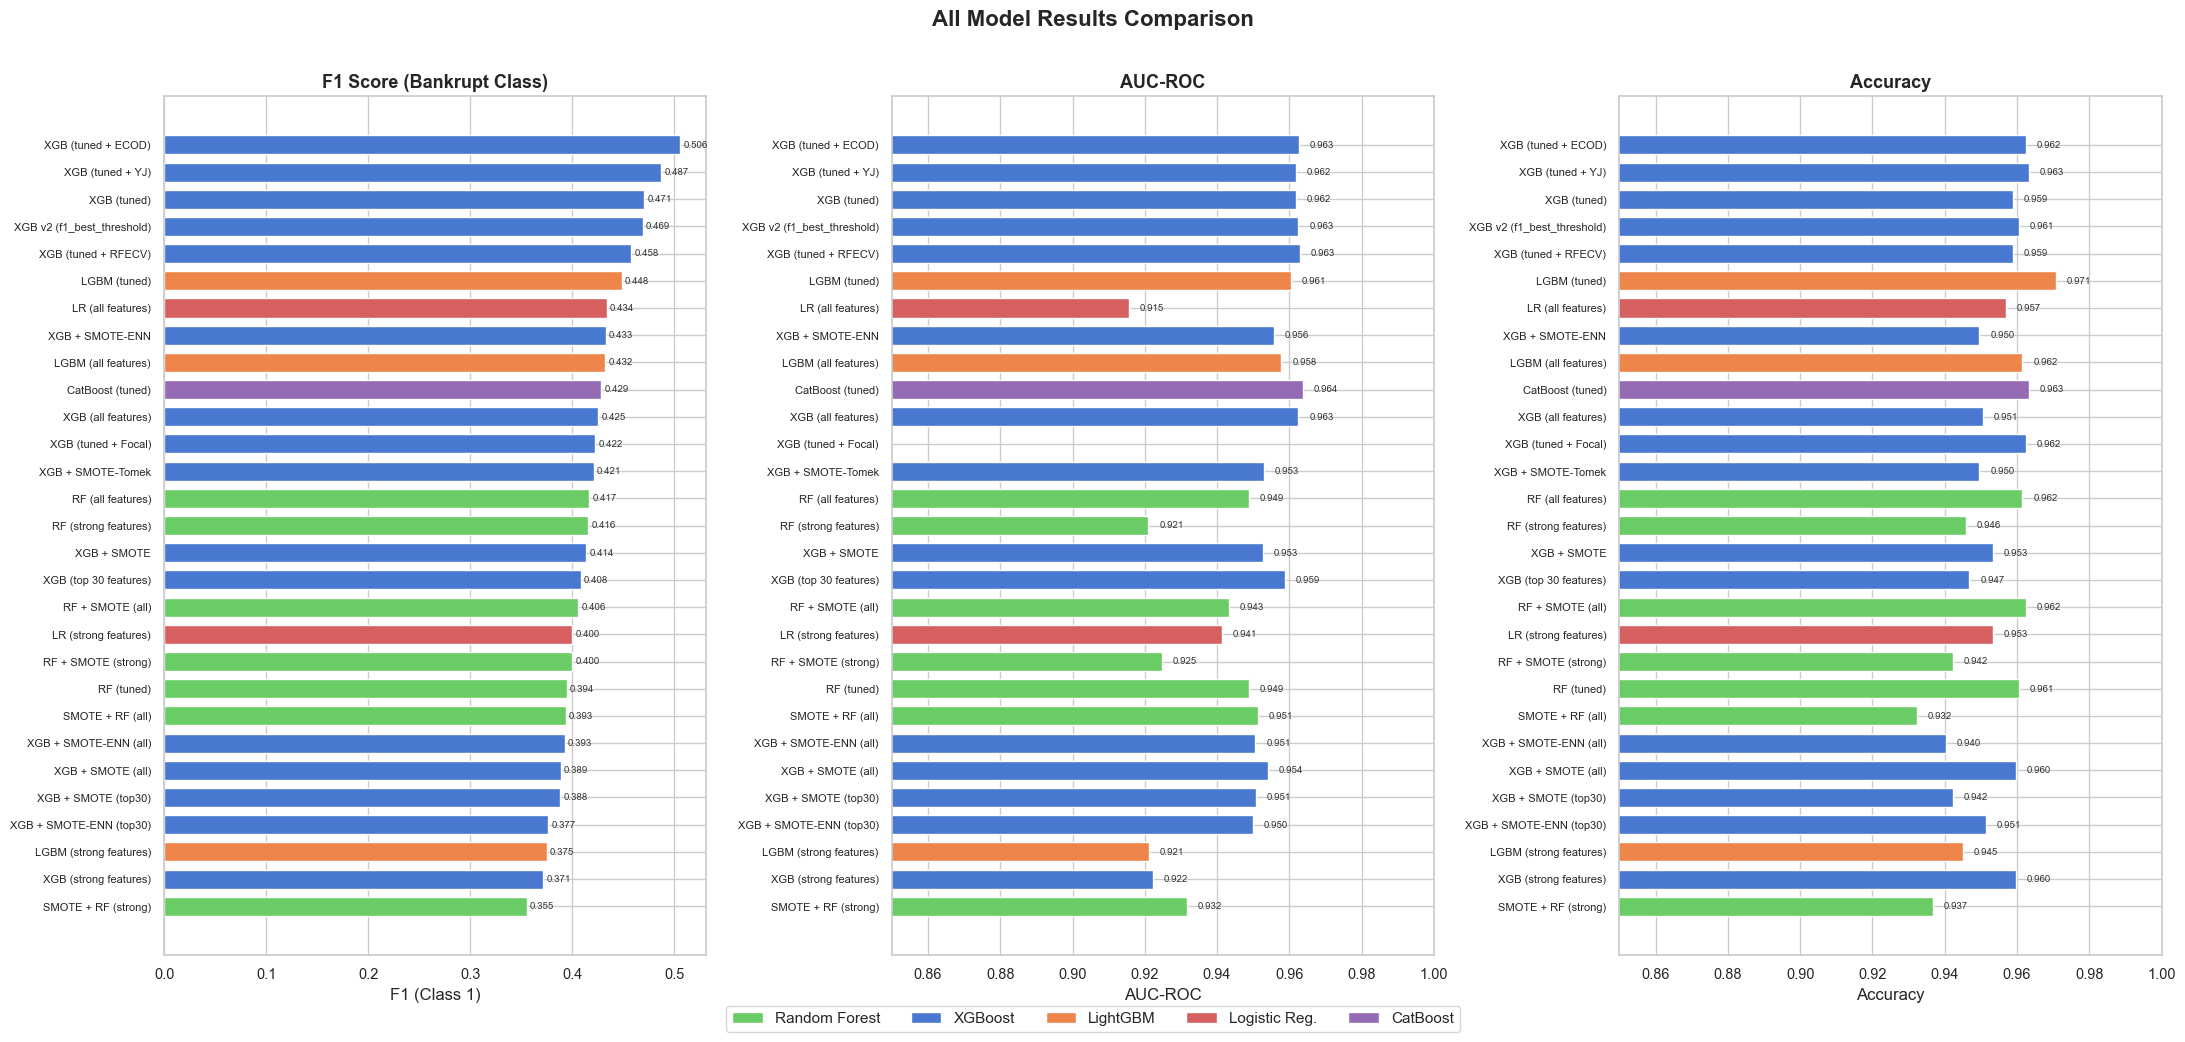

Saved → model_comparison.png


In [ ]:
sns.set_theme(style="whitegrid", font_scale=0.95)
palette = sns.color_palette("muted")  # seaborn muted palette

# ── Only use rows with full metrics ──────────────────────────────────────────
plot_df = summary_df.dropna(subset=["Accuracy"]).copy()
plot_df = plot_df.sort_values("F1 (Class 1)", ascending=True).reset_index(drop=True)

color_map = {
    "Random Forest": palette[2],
    "XGBoost":       palette[0],   
    "LightGBM":      palette[1],
    "Logistic Reg.": palette[3],
    "CatBoost":      palette[4],
}
colors = [color_map[t] for t in plot_df["Model Type"]]

fig, axes = plt.subplots(1, 3, figsize=(22, 10))

metrics = [
    ("F1 (Class 1)", "F1 Score (Bankrupt Class)", None),
    ("AUC-ROC",      "AUC-ROC",                   (0.85, 1.0)),
    ("Accuracy",     "Accuracy",                   (0.85, 1.0)),
]

for ax, (col, title, xlim) in zip(axes, metrics):
    bars = ax.barh(plot_df["Model"], plot_df[col], color=colors, edgecolor="white", height=0.7)
    ax.set_xlabel(col, fontsize=12)
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.tick_params(axis='y', labelsize=8)
    if xlim:
        ax.set_xlim(xlim)
    # 在条形末端标注数值
    for bar, val in zip(bars, plot_df[col]):
        ax.text(bar.get_width() + 0.003, bar.get_y() + bar.get_height()/2,
                f"{val:.3f}", va='center', fontsize=7, color='#333333')

# ── Legend ────────────────────────────────────────────────────────────────────
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=color_map[n], label=n) for n in color_map]
fig.legend(handles=legend_elements, loc="lower center", ncol=5, fontsize=11,
           bbox_to_anchor=(0.5, -0.02), frameon=True, edgecolor='#cccccc')

fig.suptitle("All Model Results Comparison", fontsize=16, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → model_comparison.png")